# EDA: Salud mental en el sector tecnológico

## 1. Introducción

Este proyecto analiza la encuesta «Mental Health in Tech Survey» de OSMI, realizada entre 2014 y 2016 a personas que trabajan en el sector tecnológico. El dataset (data/survey.csv) tiene 1259 respuestas y 27 columnas: cada fila es una persona y cada columna es una pregunta de la encuesta.
El objetivo es entender quién busca tratamiento para su salud mental y qué factores influyen. La variable principal es treatment (si la persona ha buscado tratamiento alguna vez).
El notebook sigue este orden: primer vistazo a los datos, detección de problemas de calidad, limpieza, análisis y respuesta a las tres preguntas de partida.

## 2. Preguntas de partida

### Pregunta 1: ¿Quién busca tratamiento?
- **Columnas:** `treatment` según `identities` (hombres, mujeres, trans / no binario / otros), `Age` (en tramos), `family_history`, `no_employees` y `remote_work`.
- **Hipótesis:** las personas con antecedentes familiares buscan tratamiento con más frecuencia. Por identidad, creo e el grupo female es el que más lo busca. El tamaño de la empresa y el teletrabajo también podrían influir en quién busca tratamiento.
- **Gráfico:** barras con el porcentaje de `treatment` en cada grupo.

### Pregunta 2: ¿Lo que ofrece la empresa cambia algo?
- **Columnas:** `treatment` según `benefits`, `care_options`, `wellness_program` y `seek_help`.
- **Hipótesis:** en las empresas que ofrecen más apoyo, más gente busca tratamiento.
- **Gráfico:** barras comparando el porcentaje de `treatment` con y sin cada tipo de apoyo.
- **Precaución:** una relación no prueba que el apoyo cause el tratamiento.

### Pregunta 3: ¿Proteger la confidencialidad reduce el miedo a hablar de salud mental en el trabajo?
- **Columnas:** `mental_health_consequence`, `supervisor` y `coworkers` según `anonymity`.
- **Hipótesis:** en las empresas que protegen el anonimato de quien usa los recursos de salud mental, hay menos miedo a las consecuencias negativas y más gente hablaría con su supervisor y con sus compañeros.
- **Gráfico:** barras apiladas en porcentaje según `anonymity` (`Yes`, `No` y `Don't know`).
- **Precaución:** muchas personas responden `Don't know`; hay que tratarlo como un grupo aparte, no mezclarlo con `No`.

## 3. Carga de los datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv('data/survey.csv', na_values=["NA"])

## 4. Primer vistazo a los datos

### 4.1 Estructura

Primero miramos cómo está organizada la tabla: cuántas filas y columnas tiene, qué tipo de dato hay en cada columna y dónde faltan valores.

In [3]:
df.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


Las primeras filas confirman que cada fila es una respuesta de la encuesta y que casi todas las columnas son texto (`Yes` / `No` / `Maybe`).

In [4]:
df.shape

(1259, 27)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Timestamp                  1259 non-null   str  
 1   Age                        1259 non-null   int64
 2   Gender                     1259 non-null   str  
 3   Country                    1259 non-null   str  
 4   state                      744 non-null    str  
 5   self_employed              1241 non-null   str  
 6   family_history             1259 non-null   str  
 7   treatment                  1259 non-null   str  
 8   work_interfere             995 non-null    str  
 9   no_employees               1259 non-null   str  
 10  remote_work                1259 non-null   str  
 11  tech_company               1259 non-null   str  
 12  benefits                   1259 non-null   str  
 13  care_options               1259 non-null   str  
 14  wellness_program           1259 non

In [6]:
df.isna().sum()

Timestamp                       0
Age                             0
Gender                          0
Country                         0
state                         515
self_employed                  18
family_history                  0
treatment                       0
work_interfere                264
no_employees                    0
remote_work                     0
tech_company                    0
benefits                        0
care_options                    0
wellness_program                0
seek_help                       0
anonymity                       0
leave                           0
mental_health_consequence       0
phys_health_consequence         0
coworkers                       0
supervisor                      0
mental_health_interview         0
phys_health_interview           0
mental_vs_physical              0
obs_consequence                 0
comments                     1095
dtype: int64

- El dataset tiene 1259 filas y 27 columnas.
- Casi todas las columnas son categóricas: solo `Age` es numérica. `Timestamp` también está guardada como texto, así que habrá que convertirla en fecha (sección 6.5).
- Cuatro columnas tienen valores vacíos: `comments` (1095), `state` (515), `work_interfere` (264) y `self_employed` (18).

In [12]:
df.columns

Index(['Timestamp', 'Age', 'Gender', 'Country', 'state', 'self_employed',
       'family_history', 'treatment', 'work_interfere', 'no_employees',
       'remote_work', 'tech_company', 'benefits', 'care_options',
       'wellness_program', 'seek_help', 'anonymity', 'leave',
       'mental_health_consequence', 'phys_health_consequence', 'coworkers',
       'supervisor', 'mental_health_interview', 'phys_health_interview',
       'mental_vs_physical', 'obs_consequence', 'comments'],
      dtype='str')

Las 27 columnas se pueden agrupar en tres bloques: el perfil de la persona (edad, género, país), su salud mental (`treatment`, `family_history`, `work_interfere`) y su entorno laboral (empresa, apoyo y miedo a hablar del tema).

### 4.2 Estadísticas básicas

Ahora resumimos las columnas numéricas y las de texto para detectar valores raros.

In [7]:
df.describe()

,Age
count,1.259000e+03
mean,7.942815e+07
std,2.818299e+09
min,-1.726000e+03
25%,2.700000e+01
50%,3.100000e+01
75%,3.600000e+01
max,1.000000e+11


In [8]:
df["Age"].sort_values().head(10)

715    -1726
143      -29
1127      -1
734        5
989        8
1090      11
282       18
287       18
43        18
482       18
Name: Age, dtype: int64

In [9]:
df["Age"].sort_values().tail(10)

466              57
471              58
1236             60
297              60
952              61
520              62
560              65
1182             72
364             329
390     99999999999
Name: Age, dtype: int64

En `Age` hay valores imposibles (-1726, -29, -1, 329 y 99999999999) y valores poco creíbles para una encuesta de trabajo (5, 8 y 11). El 72 es raro, pero posible.

Por eso la media no es fiable (7,9e+07), mientras que la mediana (31 años) sí es realista. Lo corregimos en la sección 6.3.

In [11]:
df.describe(include="str")

,Timestamp,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
count,1259,1259,1259,744,1241,1259,1259,995,1259,1259,...,1259,1259,1259,1259,1259,1259,1259,1259,1259,164
unique,1246,49,48,45,2,2,2,4,6,2,...,5,3,3,3,3,3,3,3,2,160
top,2014-08-27 12:31:41,Male,United States,CA,No,No,Yes,Sometimes,6-25,No,...,Don't know,No,No,Some of them,Yes,No,Maybe,Don't know,No,* Small family business - YMMV.
freq,2,615,751,138,1095,767,637,465,290,883,...,563,490,925,774,516,1008,557,576,1075,5


- `Gender` tiene 49 valores distintos; habrá que agruparlos en categorías más amplias (sección 5.4).
- Casi el 60 % de las respuestas son de Estados Unidos.
- `treatment` está equilibrada: alrededor del 51 % responde `Yes`, así que no hace falta reequilibrarla.

### Resumen del primer vistazo

Con este primer vistazo detectamos cuatro problemas que trataremos más adelante:

- valores vacíos en cuatro columnas (sección 5.1);
- edades imposibles en `Age` (secciones 5.3 y 6.3);
- `Gender` escrito de 49 formas distintas (sección 5.4);
- `Timestamp` guardada como texto en lugar de fecha (sección 6.5).

## 5. Calidad de los datos

Aquí solo detectamos los problemas y decidimos qué hacer. No se modifica nada: las decisiones se aplican en la sección 6.

### 5.1 Valores vacíos

Objetivo: contar cuántos valores faltan en cada columna, ver dónde están y entender por qué faltan antes de decidir qué hacer.

In [116]:
missing = df.isna().sum()
pct = (missing / len(df) * 100).round(1)

In [117]:
pd.DataFrame({"missing": missing, "pct": pct}).sort_values("pct", ascending=False)

,missing,pct
comments,1095,87.0
state,515,40.9
work_interfere,264,21.0
self_employed,18,1.4
seek_help,0,0.0
obs_consequence,0,0.0
mental_vs_physical,0,0.0
phys_health_interview,0,0.0
mental_health_interview,0,0.0
supervisor,0,0.0


Qué vemos: solo cuatro columnas tienen valores vacíos: `comments` (87,0 %), `state` (40,9 %), `work_interfere` (21,0 %) y `self_employed` (1,4 %). El resto está completo.

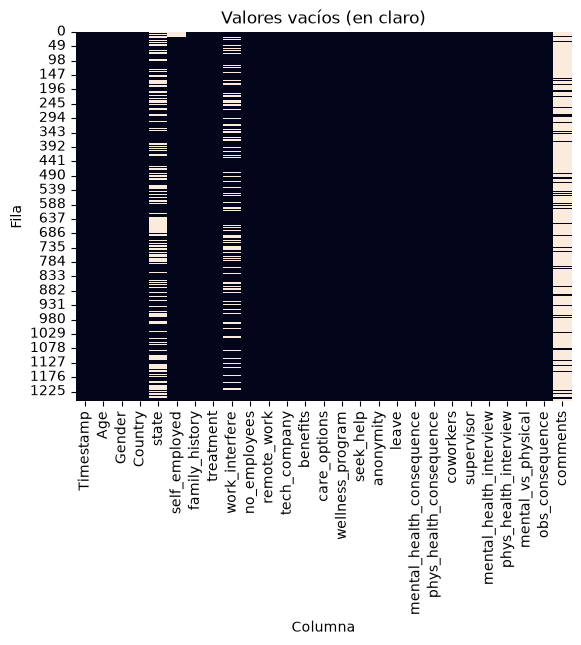

In [118]:
sns.heatmap(df.isna(), cbar=False)
plt.title("Valores vacíos (en claro)")
plt.xlabel("Columna")
plt.ylabel("Fila")
plt.show()

Qué vemos: los vacíos de `self_employed` están todos juntos arriba, en las primeras filas. Probablemente esa pregunta se añadió a la encuesta después de empezar.

Ahora comprobamos la causa de cada hueco: las filas vacías de `self_employed`, el país de las personas sin `state` y la relación entre `work_interfere` y `treatment`.

In [17]:
df[df["self_employed"].isna()].index.tolist()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

In [18]:
df[df["state"].isna()]["Country"].value_counts().head()

Country
United Kingdom    185
Canada             72
Germany            45
Netherlands        27
Ireland            27
Name: count, dtype: int64

In [19]:
pd.crosstab(df["treatment"], df["work_interfere"].isna())

work_interfere,False,True
treatment,,
No,362,260
Yes,633,4


Qué vemos: los vacíos tienen una causa, no son errores al azar.

- `comments` es texto libre y opcional.
- `state` solo se pregunta a las personas de Estados Unidos; casi todas las filas vacías son de otros países.
- `work_interfere` está vacía casi siempre (260 de 264) en las personas que no han buscado tratamiento, porque la pregunta solo tiene sentido si hay un problema de salud mental.
- `self_employed` está vacía solo en las 18 primeras filas.

#### Decisión sobre los valores vacíos

| Columna | % vacío | Decisión | Razón |
|---|---|---|---|
| `comments` | 87.0 | Eliminar la columna | Es texto libre y casi vacío; no sirve para los gráficos. |
| `state` | 40.9 | Eliminar la columna | Solo existe para Estados Unidos. Comparamos entre países, no entre estados. |
| `work_interfere` | 21.0 | Mantener y rellenar con `No aplica` | Es la única columna que mide si el problema afecta al trabajo. No se eliminan filas porque los vacíos no son al azar y se perdería el 42 % de las personas sin tratamiento. |
| `self_employed` | 1.4 | Mantener y rellenar con `Desconocido` | Son solo 18 filas. No sabemos qué habrían respondido, así que no inventamos una respuesta. |

Estas decisiones se aplican en la sección 6.2.

### 5.2 Duplicados

Objetivo: comprobar si hay respuestas repetidas, que contarían dos veces en el análisis.

In [16]:
df.duplicated().sum()

np.int64(0)

Qué vemos: hay 0 filas duplicadas; cada fila es una respuesta distinta.

Decisión: no hace falta hacer nada.

### 5.3 Edades imposibles

Objetivo: decidir qué hacer con los valores absurdos de `Age` que vimos en la sección 4.2.

Qué vemos: hay edades imposibles (-1726, -29, -1, 329 y 99999999999) y edades poco creíbles para una encuesta de trabajo (5, 8 y 11). En total son 8 filas.

#### Decisión sobre `Age`

Solo consideramos válidas las edades entre 18 y 80 años. Las demás pasan a vacío (NaN), pero conservamos la fila porque el resto de sus respuestas sigue siendo útil. No inventamos una edad que no conocemos.

Esta decisión se aplica en la sección 6.3.

### 5.4 Género escrito de muchas formas

Objetivo: entender las 49 escrituras distintas de `Gender` y decidir cómo agruparlas sin perder información.

In [36]:
df["Gender"].value_counts().to_string()

'Gender\nMale                                              615\nmale                                              206\nFemale                                            121\nM                                                 116\nfemale                                             62\nF                                                  38\nm                                                  34\nf                                                  15\nMake                                                4\nWoman                                               3\nMale                                                3\nCis Male                                            2\nFemale                                              2\nMan                                                 2\nFemale (trans)                                      2\nMale-ish                                            1\nmaile                                               1\nTrans-female                                        1\nC

Qué vemos: casi todas las respuestas son variantes de `Male` o `Female` (mayúsculas, abreviaturas como `M` y `F`, faltas de ortografía y espacios al final). Después hay respuestas únicas: identidades trans, no binarias o queer, y algunas que no son un género (`Nah`, `All`, `p`).

#### Decisión sobre `Gender`

Clasificamos a cada persona según lo que escribió, sin adivinar por ella.

| Respuestas | Qué hacemos |
|---|---|
| Variantes de hombre (`M`, `male`, `Make`, `maile`, `cis male`...) y las dudosas que contienen la palabra male (`Male-ish`, `Guy (-ish)`...) | `Male` en `Gender` |
| Variantes de mujer (`F`, `woman`, `femail`, `cis female`...) | `Female` en `Gender` |
| Respuestas que no son un género (`Nah`, `All`, `p`, `A little about you`) | NaN en `Gender` |
| Identidades trans, no binarias, queer, fluid, agender, etc. (14 personas) | Se dejan tal como están en `Gender` |

Además creamos una columna nueva, `identities`, con tres valores: `Male`, `Female` y `Trans / non-binary / other`. El tercer grupo reúne a las mujeres y hombres trans y a las identidades no binarias.

Límite: el tercer grupo tiene solo 14 personas sobre 1259, así que sus resultados son orientativos, no concluyentes.

Estas decisiones se aplican en la sección 6.4.

### 5.5 Tipos de datos

Objetivo: revisar si cada columna tiene el tipo correcto y decidir qué convertir. Un tipo incorrecto impide hacer operaciones útiles (por ejemplo, sacar el año de una fecha guardada como texto).

In [50]:
df.dtypes.value_counts()

str      26
int64     1
Name: count, dtype: int64

In [51]:
df["Timestamp"].head()

0    2014-08-27 11:29:31
1    2014-08-27 11:29:37
2    2014-08-27 11:29:44
3    2014-08-27 11:29:46
4    2014-08-27 11:30:22
Name: Timestamp, dtype: str

In [52]:
df["Timestamp"].dtype

<StringDtype(storage='python', na_value=nan)>

Qué vemos: 26 columnas son texto y solo `Age` es numérica (entero). `Timestamp` (fecha y hora de cada respuesta) está guardada como texto, no como fecha.

Decisión:

| Columna | Tipo actual | Decisión | Razón |
|---|---|---|---|
| `Timestamp` | texto | convertir a `datetime` | poder sacar año y mes, y ver tendencias en el tiempo |
| `Age` | entero | sin cambio aquí (en 6.3 pasa a `float` por los NaN) | los enteros no admiten NaN |
| resto | texto | dejar como están | son categorías, no números |

La conversión se aplica en la sección 6.5.

## 6. Limpieza de los datos

Aquí aplicamos las decisiones de la sección 5, siempre sobre la copia `df_clean`.

### 6.1 Copia del dataset

Objetivo: crear una copia del dataset para limpiar sin tocar los datos originales.

In [20]:
df_clean = df.copy()

In [21]:
df_clean.shape

(1259, 27)

In [22]:
df_clean is df

False

Qué hicimos: `df.copy()` crea un objeto nuevo e independiente (`.copy()` duplica los datos; `df_clean = df` solo daría otro nombre al mismo objeto).

Verificación: `df_clean` tiene la misma forma que `df` (1259 filas y 27 columnas) y `df_clean is df` da `False`, así que son dos objetos distintos.

Trabajamos con esta copia para no perder los datos originales y poder comparar antes y después.

### 6.2 Columnas y valores vacíos

Objetivo: aplicar las decisiones de la sección 5.1.

- `comments` y `state`: se eliminan (texto libre casi vacío; `state` solo existe para EE. UU.).
- `work_interfere`: se rellena con `No aplica` (los vacíos son sobre todo personas sin tratamiento).
- `self_employed`: se rellena con `Desconocido` (solo 18 filas y no inventamos la respuesta).

In [23]:
df_clean = df_clean.drop(columns=["comments", "state"])

In [24]:
df_clean.shape

(1259, 25)

In [25]:
df_clean["work_interfere"] = df_clean["work_interfere"].fillna("No aplica")

In [26]:
df_clean["self_employed"] = df_clean["self_employed"].fillna("Desconocido")

In [27]:
df_clean.isna().sum().sum()

np.int64(0)

In [29]:
df.shape

(1259, 27)

Qué hicimos: borramos las columnas `comments` y `state`, y rellenamos los vacíos de `work_interfere` con `No aplica` y los de `self_employed` con `Desconocido`.

Verificación: `df_clean` tiene ahora 25 columnas y ya no quedan valores vacíos (la suma es 0). `df` sigue con sus 27 columnas, sin cambios.

### 6.3 Edades

Objetivo: aplicar la decisión de la sección 5.3 (solo valen las edades entre 18 y 80 años). Primero contamos y miramos las filas afectadas, y después las pasamos a NaN.

In [30]:
mask = (df_clean["Age"] < 18) | (df_clean["Age"] > 80)
mask.sum()

np.int64(8)

In [31]:
df_clean.loc[mask, "Age"].sort_values()

715           -1726
143             -29
1127             -1
734               5
989               8
1090             11
364             329
390     99999999999
Name: Age, dtype: int64

In [32]:
df_clean["Age"] = df_clean["Age"].mask(mask)

In [33]:
df_clean["Age"].isna().sum()

np.int64(8)

In [34]:
df_clean["Age"].describe()

count    1251.000000
mean       32.076739
std         7.288272
min        18.000000
25%        27.000000
50%        31.000000
75%        36.000000
max        72.000000
Name: Age, dtype: float64

Verificación:

- `count` ahora está en 1251, lo que confirma los 8 NaN.
- `min` es 18 y `max` es 72: los valores imposibles ya no aparecen (pasaron a NaN).
- La media es 32,1 en lugar de 7,9e+07: la limpieza corrigió los outliers. La mediana es 31.
- `Age` cambió a `float64`, lo que permite tener NaN.

### 6.4 Género e `identities`

Objetivo: aplicar la decisión de la sección 5.4. Primero limpiamos `Gender` y después creamos la columna `identities`.

Primero preparamos las listas. `g` es `Gender` sin espacios y en minúsculas, para comparar sin que importen mayúsculas ni espacios. `male`, `female` e `invalid` contienen las escrituras que reconocemos (erratas, variantes `cis` y respuestas dudosas que contienen la palabra male).

In [41]:
g = df_clean["Gender"].str.strip().str.lower()
male = ["male", "m", "make", "maile", "mal", "msle", "mail", "malr", "man",
        "cis male", "male (cis)", "cis man",
        "male-ish", "guy (-ish) ^_^", "something kinda male?",
        "ostensibly male, unsure what that really means"]
female = ["female", "f", "woman", "femake", "femail",
          "cis female", "female (cis)", "cis-female/femme"]
invalid = ["nah", "all", "p", "a little about you"]

Ahora aplicamos las listas sobre `Gender`. Las respuestas que no son un género (`Nah`, `All`, `p`, `A little about you`) pasan a NaN. Lo que no está en ninguna lista (trans, no binario, fluido, queer, etc.) queda tal como lo escribió la persona.

In [42]:
df_clean.loc[g.isin(male), "Gender"] = "Male"
df_clean.loc[g.isin(female), "Gender"] = "Female"
df_clean.loc[g.isin(invalid), "Gender"] = pd.NA

In [43]:
df_clean["Gender"].value_counts(dropna=False)

Gender
Male                        994
Female                      247
NaN                           4
Female (trans)                2
Trans-female                  1
queer/she/they                1
non-binary                    1
Enby                          1
fluid                         1
Genderqueer                   1
Androgyne                     1
Agender                       1
male leaning androgynous      1
Trans woman                   1
Neuter                        1
queer                         1
Name: count, dtype: int64

#### Nueva columna `identities`

Creamos `identities` con 3 grupos: `Male`, `Female` y `Trans / non-binary / other`. Empieza con el tercer grupo para todos y luego se sobrescribe con `Male` y `Female` según `Gender`; donde `Gender` es NaN, `identities` también.

In [44]:
df_clean["identities"] = "Trans / non-binary / other"
df_clean.loc[df_clean["Gender"] == "Male", "identities"] = "Male"
df_clean.loc[df_clean["Gender"] == "Female", "identities"] = "Female"
df_clean.loc[df_clean["Gender"].isna(), "identities"] = pd.NA

In [45]:
df_clean["identities"].value_counts(dropna=False)

identities
Male                          994
Female                        247
Trans / non-binary / other     14
NaN                             4
Name: count, dtype: int64

In [46]:
df_clean["identities"].isna().sum()

np.int64(4)

Qué hicimos: limpiamos `Gender` (erratas y variantes `cis` agrupadas en `Male` o `Female`, respuestas no válidas a NaN) y creamos `identities` con 3 grupos, como pidió la profesora. `Gender` se mantiene para el detalle.

Verificación: `Male` 994 + `Female` 247 + `Trans / non-binary / other` 14 + NaN 4 = 1259 filas, y `isna().sum()` da 4.

Limitación: el tercer grupo reúne a personas trans, no binarias y otras identidades por una decisión práctica, no porque no sean mujeres u hombres. Con solo 14 respuestas, sus resultados serán orientativos.

### 6.5 Fechas (`Timestamp`)

Objetivo: aplicar la decisión de la sección 5.5 y convertir `Timestamp` de texto a `datetime`.

In [53]:
df_clean["Timestamp"] = pd.to_datetime(df_clean["Timestamp"])

In [54]:
df_clean["Timestamp"].dtype

dtype('<M8[us]')

In [55]:
df_clean["Timestamp"].min(), df_clean["Timestamp"].max()

(Timestamp('2014-08-27 11:29:31'), Timestamp('2016-02-01 23:04:31'))

In [56]:
df_clean["Timestamp"].dt.year.value_counts().sort_index()

Timestamp
2014    1190
2015      68
2016       1
Name: count, dtype: int64

Qué hicimos: convertimos `Timestamp` a `datetime` con `pd.to_datetime`. Si algún valor no se pudiera leer, pandas daría un error; no lo dio.

Verificación:

- El tipo es ahora `datetime64`.
- Las respuestas van del 27/08/2014 al 01/02/2016.
- Por año: 2014 tiene 1190 respuestas, 2015 tiene 68 y 2016 solo 1.

Limitación: casi todas las respuestas (1135 de 1259) llegaron en agosto de 2014. Por eso un gráfico de tendencia en el tiempo no sería fiable; en la sección de tendencias compararemos grupos en lugar de años (el brief lo permite).

### 6.6 Guardar el dataset limpio

Objetivo: guardar `df_clean` en un archivo nuevo, `data/survey_clean.csv`, para no repetir la limpieza y no tocar `data/survey.csv` (el original).

In [57]:
df_clean.to_csv("data/survey_clean.csv", index=False)

In [58]:
pd.read_csv("data/survey_clean.csv", parse_dates=["Timestamp"]).shape

(1259, 26)

Qué hicimos: guardamos `df_clean` con `index=False` para que no se añada una columna con los números de fila.

Verificación: al volver a leer el archivo, la forma es (1259, 26): 27 columnas originales, menos `comments` y `state`, más `identities`.

Nota: un CSV no guarda los tipos. Por eso, al leerlo otra vez, hay que usar `parse_dates=["Timestamp"]` para que `Timestamp` vuelva a ser una fecha.

## 7. Análisis

Aquí exploramos los datos limpios (`df_clean`): primero cada variable por separado (7.1) y después las relaciones entre dos variables (7.2).

### 7.1 Análisis univariado

Objetivo: mirar una variable cada vez para ver cómo se distribuye. Elegimos el gráfico según el tipo de variable (guía: data-to-viz.com).

| Variable | Tipo | Gráfico | Por qué |
|---|---|---|---|
| `Age` | numérica | histograma + boxplot | ver la forma de la distribución y los valores extremos |
| `treatment` | categórica | countplot | ver si las respuestas están equilibradas (variable objetivo) |
| `identities` | categórica | countplot | ver el tamaño de cada grupo |
| `family_history` | categórica | countplot | factor de la pregunta 1: cuántas personas tienen antecedentes familiares |
| `no_employees` | categórica ordenada | countplot ordenado | factor de la pregunta 1: ver cómo se reparten los tamaños de empresa |
| `anonymity` | categórica | countplot | variable de la pregunta 3: ver el tamaño de cada grupo (el grupo `No` es pequeño) |
| `Country` | categórica | barras de los 5 países principales | contexto: de dónde vienen las respuestas (límite del estudio) |

**Age:**

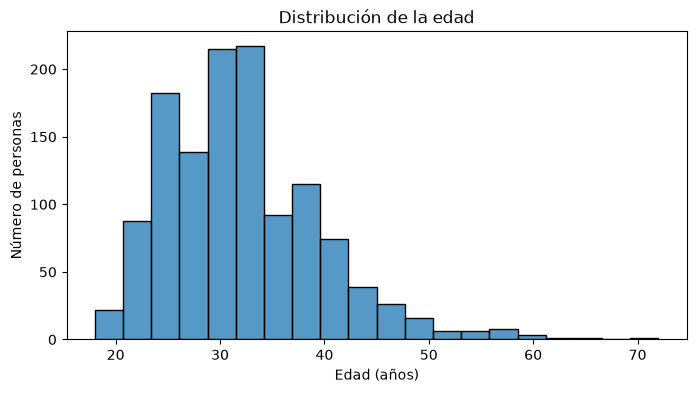

In [60]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df_clean, x="Age", bins=20)
plt.title("Distribución de la edad")
plt.xlabel("Edad (años)")
plt.ylabel("Número de personas")
plt.show()

**Qué vemos:** la mayoría de las personas tiene entre 25 y 40 años. El pico está alrededor de los 30 años (las barras más altas, entre 28 y 34 años). A partir de los 45 años hay muy pocas personas, y casi nadie supera los 55. La distribución se alarga hacia la derecha.

**Interpretación:** la encuesta refleja una población joven (edad mediana de 31 años). Las personas mayores de 50 años están poco representadas, así que los resultados para ese grupo serían poco fiables.

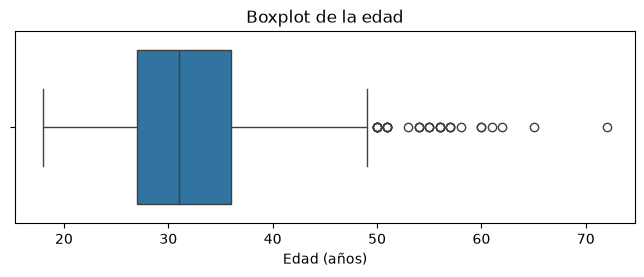

In [66]:
plt.figure(figsize=(8, 2.5))
sns.boxplot(data=df_clean, x="Age")
plt.title("Boxplot de la edad")
plt.xlabel("Edad (años)")
plt.show()

**Qué vemos:** la mitad de las personas tiene entre 27 y 36 años y la mediana es de 31. El boxplot marca como valores extremos a 32 personas (el 2,6 %) de más de 49 años, hasta un máximo de 72.

**Interpretación:** estos valores son edades reales y posibles (personas mayores que trabajan), no errores como los de la limpieza. Por eso los conservamos: solo representan a un grupo pequeño.

**treatment:**

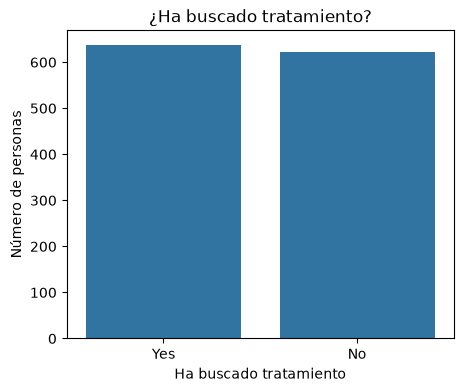

In [61]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df_clean, x="treatment")
plt.title("¿Ha buscado tratamiento?")
plt.xlabel("Ha buscado tratamiento")
plt.ylabel("Número de personas")
plt.show()

In [63]:
df_clean["treatment"].value_counts(normalize=True) * 100

treatment
Yes    50.595711
No     49.404289
Name: proportion, dtype: float64

**Qué vemos:** las dos respuestas están casi igual de repartidas: 637 personas (50,6 %) han buscado tratamiento y 622 (49,4 %) no.

**Interpretación:** la variable está equilibrada, así que podemos comparar grupos sin tener que corregir nada. Ojo: `treatment` indica quién ha buscado tratamiento, no quién sufre un problema de salud mental.

**identities:**

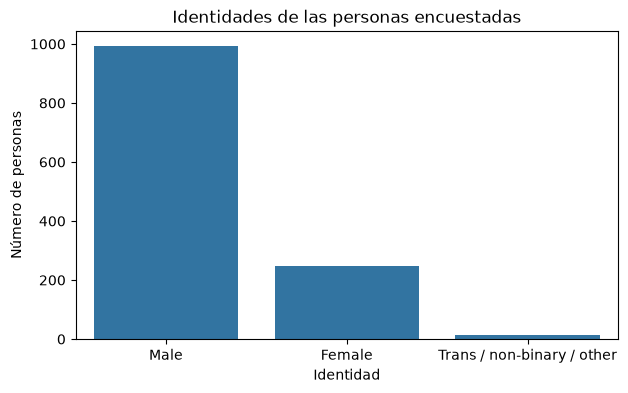

In [64]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="identities", order=["Male", "Female", "Trans / non-binary / other"])
plt.title("Identidades de las personas encuestadas")
plt.xlabel("Identidad")
plt.ylabel("Número de personas")
plt.show()

In [65]:
df_clean["identities"].value_counts(normalize=True) * 100

identities
Male                          79.203187
Female                        19.681275
Trans / non-binary / other     1.115538
Name: proportion, dtype: float64

**Qué vemos:** la gran mayoría de las personas encuestadas son hombres (994, el 79,2 %), seguidas de las mujeres (247, el 19,7 %). El grupo «Trans / non-binary / other» es muy pequeño: solo 14 personas (el 1,1 %). Las 4 respuestas sin identidad válida no aparecen en el gráfico.

**Interpretación:** la encuesta tiene muchos más hombres que mujeres, y el tercer grupo es demasiado pequeño para sacar conclusiones fiables: sus resultados serán solo orientativos. Al comparar grupos, usaremos porcentajes dentro de cada grupo y no números absolutos.

**family_history:**

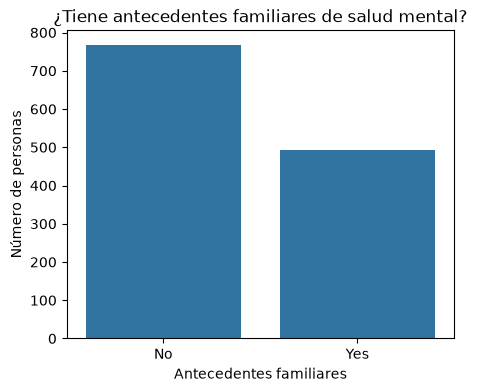

In [67]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df_clean, x="family_history")
plt.title("¿Tiene antecedentes familiares de salud mental?")
plt.xlabel("Antecedentes familiares")
plt.ylabel("Número de personas")
plt.show()


In [68]:
df_clean["family_history"].value_counts(normalize=True) * 100

family_history
No     60.921366
Yes    39.078634
Name: proportion, dtype: float64

**Qué vemos:** la mayoría de las personas (767, el 60,9 %) no tiene antecedentes familiares; 492 (el 39,1 %) sí los tiene.

**Interpretación:** casi 4 de cada 10 personas tienen antecedentes familiares, un grupo suficientemente grande para compararlo con `treatment` en el análisis bivariado.

**no_employees:**

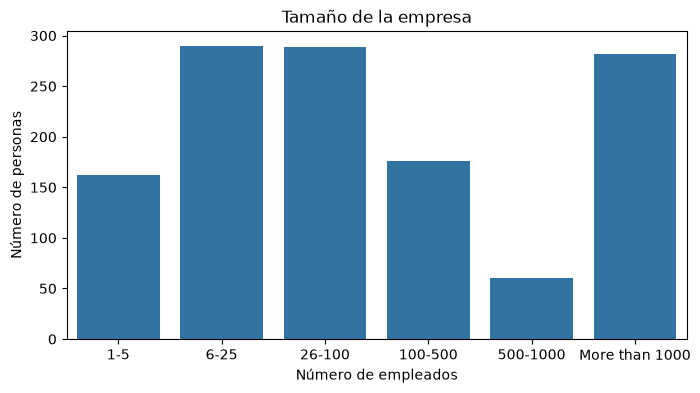

In [69]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x="no_employees",
              order=["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"])
plt.title("Tamaño de la empresa")
plt.xlabel("Número de empleados")
plt.ylabel("Número de personas")
plt.show()

In [70]:
df_clean["no_employees"].value_counts(normalize=True).reindex(
    ["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"]) * 100

no_employees
1-5               12.867355
6-25              23.034154
26-100            22.954726
100-500           13.979349
500-1000           4.765687
More than 1000    22.398729
Name: proportion, dtype: float64

**Qué vemos:** las respuestas se reparten bastante entre los tamaños de empresa. Los grupos más grandes son 6-25 empleados (290 personas, el 23,0 %), 26-100 (289, el 23,0 %) y más de 1000 (282, el 22,4 %). El grupo más pequeño es 500-1000 empleados, con solo 60 personas (el 4,8 %).

**Interpretación:** hay respuestas tanto de empresas pequeñas como de grandes, así que podemos comparar `treatment` según el tamaño. Hay que tener cuidado con el grupo de 500-1000 empleados, que tiene pocas respuestas.

**anonymity:**

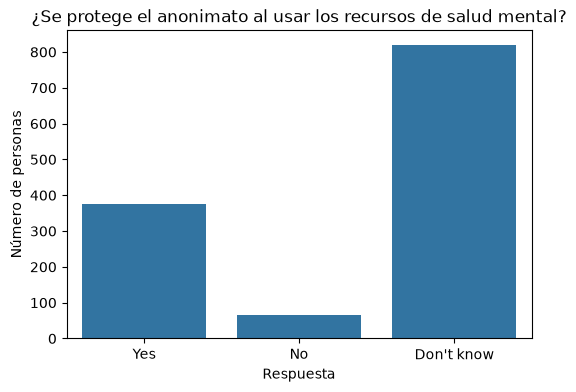

In [71]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x="anonymity", order=["Yes", "No", "Don't know"])
plt.title("¿Se protege el anonimato al usar los recursos de salud mental?")
plt.xlabel("Respuesta")
plt.ylabel("Número de personas")
plt.show()

In [72]:
df_clean["anonymity"].value_counts(normalize=True).reindex(["Yes", "No", "Don't know"]) * 100

anonymity
Yes           29.785544
No             5.162828
Don't know    65.051628
Name: proportion, dtype: float64

**Qué vemos:** la mayoría de las personas (819, el 65,1 %) no sabe si se protege su anonimato. 375 (el 29,8 %) dicen que sí y solo 65 (el 5,2 %) dicen que no.

**Interpretación:** el grupo «No» es muy pequeño (65 personas), así que sus resultados serán solo orientativos en la pregunta 3. Además, que dos de cada tres personas no sepan la respuesta sugiere que las empresas comunican poco sobre este tema.

**Country:**

In [73]:
top_countries = df_clean["Country"].value_counts().head(5)
top_countries

Country
United States     751
United Kingdom    185
Canada             72
Germany            45
Netherlands        27
Name: count, dtype: int64

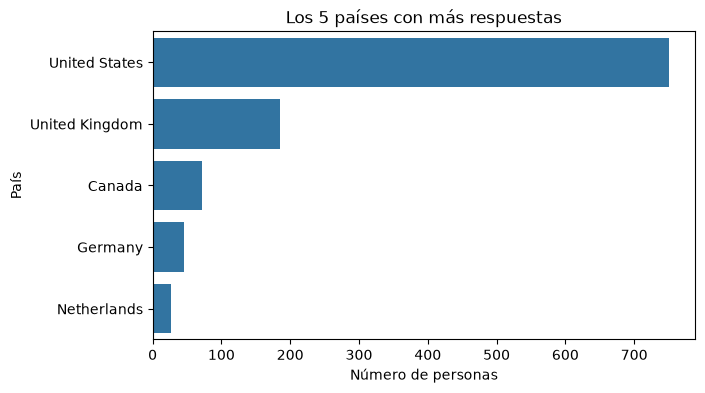

In [74]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, y="Country", order=top_countries.index)
plt.title("Los 5 países con más respuestas")
plt.xlabel("Número de personas")
plt.ylabel("País")
plt.show()

**Por qué solo 5 países:** hay 48 países en total, pero la mayoría tiene muy pocas respuestas (muchos solo 1 a 5 personas). Un gráfico con 48 barras sería ilegible y no aportaría información útil, porque aquí solo queremos saber de dónde vienen las respuestas. Los 5 países principales reúnen el 85,8 % de las respuestas. Los datos completos siguen en `df_clean`.

**Qué vemos:** más de la mitad de las respuestas vienen de Estados Unidos (751 personas, el 59,7 %), seguido del Reino Unido (185, el 14,7 %) y Canadá (72, el 5,7 %). Los otros 43 países reúnen solo el 14,2 %.

**Interpretación:** los resultados reflejan sobre todo la situación en Estados Unidos. No es posible comparar países con tan pocas respuestas, y por eso `Country` no es una de nuestras variables de análisis.


### 7.2 Análisis bivariado

Objetivo: mirar la relación entre dos variables para responder a las preguntas de partida (sección 2). Casi todas las relaciones son contra `treatment`. Como las dos variables son categóricas, usamos una tabla de contingencia (`crosstab` con `normalize="index"`, que da el porcentaje dentro de cada grupo) y un gráfico de barras con esos porcentajes (guía: data-to-viz.com).

| Pregunta | Relación | Gráfico | Por qué |
|---|---|---|---|
| P1 | `treatment` según `family_history` | barras de % | comparar el % de tratamiento con y sin antecedentes |
| P1 | `treatment` según `identities` | barras de % | comparar el % de tratamiento entre grupos (el grupo trans es pequeño) |
| P1 | `treatment` según `Age` (en tramos) | barras de % ordenadas | ver si el % cambia con la edad |
| P1 | `treatment` según `no_employees` | barras de % ordenadas | ver si el % cambia con el tamaño de la empresa |
| P1 | `treatment` según `remote_work` | barras de % | comparar el % entre quien teletrabaja y quien no |
| P2 | `treatment` según `benefits`, `care_options`, `wellness_program`, `seek_help` | barras de % | comparar el % con y sin cada tipo de apoyo |
| P3 | `mental_health_consequence`, `supervisor`, `coworkers` según `anonymity` | barras apiladas al 100 % | ver cómo se reparten las respuestas en cada grupo de anonimato |

#### 7.2.1 Pregunta 1: ¿Quién busca tratamiento?

Objetivo: ver en qué grupos el porcentaje de personas que han buscado tratamiento (`treatment = Yes`) es mayor.

**treatment según family_history:**

In [78]:
tabla_fh = pd.crosstab(df_clean["family_history"], df_clean["treatment"], normalize="index") * 100
tabla_fh.round(1)


treatment,No,Yes
family_history,,
No,64.5,35.5
Yes,25.8,74.2


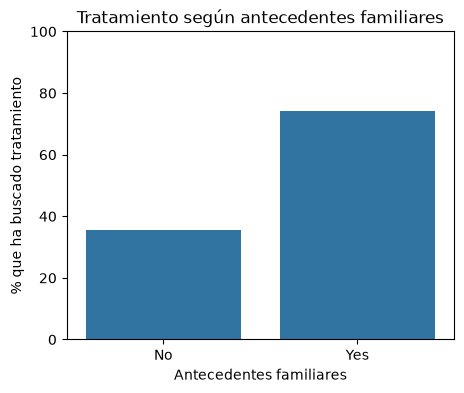

In [79]:
plt.figure(figsize=(5, 4))
sns.barplot(x=tabla_fh.index, y=tabla_fh["Yes"])
plt.title("Tratamiento según antecedentes familiares")
plt.xlabel("Antecedentes familiares")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()


**Qué vemos:** entre las personas sin antecedentes familiares, el 35,5 % ha buscado tratamiento (272 de 767). Entre las que sí tienen antecedentes, el 74,2 % lo ha buscado (365 de 492). La diferencia es de unos 39 puntos.

**Interpretación:** tener antecedentes familiares va unido a buscar tratamiento mucho más a menudo, lo que va en el sentido de nuestra hipótesis. Es una relación, no una causa: otros factores (por ejemplo, si la salud mental ha afectado al trabajo) pueden influir.

**treatment según identities:**

In [82]:
tabla_id = pd.crosstab(df_clean["identities"], df_clean["treatment"], normalize="index") * 100
tabla_id.round(1)


treatment,No,Yes
identities,,
Female,31.2,68.8
Male,54.5,45.5
Trans / non-binary / other,21.4,78.6


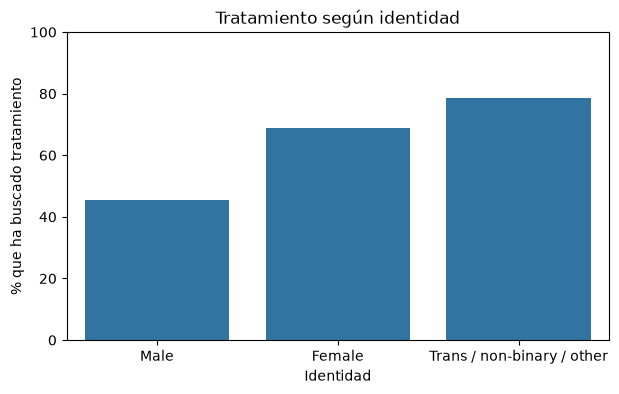

In [83]:
plt.figure(figsize=(7, 4))
sns.barplot(x=tabla_id.index, y=tabla_id["Yes"],
            order=["Male", "Female", "Trans / non-binary / other"])
plt.title("Tratamiento según identidad")
plt.xlabel("Identidad")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()


**Qué vemos:** el 45,5 % de los hombres ha buscado tratamiento (452 de 994), frente al 68,8 % de las mujeres (170 de 247) y al 78,6 % del grupo «Trans / non-binary / other» (11 de 14).

**Interpretación:** entre hombres y mujeres, los grupos grandes, las mujeres buscan tratamiento bastante más a menudo (unos 23 puntos de diferencia). El grupo «Trans / non-binary / other» tiene el porcentaje más alto, pero son solo 14 personas: un cambio de una persona mueve el porcentaje unos 7 puntos, así que su resultado es solo orientativo. Es una relación, no una causa.

**treatment según Age (en tramos):**

Primero creamos los tramos de edad.

**Decisión sobre los tramos de edad**

| Tramo | Por qué |
|---|---|
| 18-25 | inicio de la carrera |
| 26-35 | el grupo más numeroso de la encuesta |
| 36-45 | carrera consolidada |
| 46+ | pocas personas (56): resultado orientativo |

In [84]:
df_clean["age_group"] = pd.cut(df_clean["Age"], bins=[17, 25, 35, 45, 120],
                               labels=["18-25", "26-35", "36-45", "46+"])
df_clean["age_group"].value_counts().sort_index()


age_group
18-25    217
26-35    701
36-45    277
46+       56
Name: count, dtype: int64

In [85]:
tabla_age = pd.crosstab(df_clean["age_group"], df_clean["treatment"], normalize="index") * 100
tabla_age.round(1)


treatment,No,Yes
age_group,,
18-25,51.6,48.4
26-35,51.4,48.6
36-45,44.8,55.2
46+,41.1,58.9


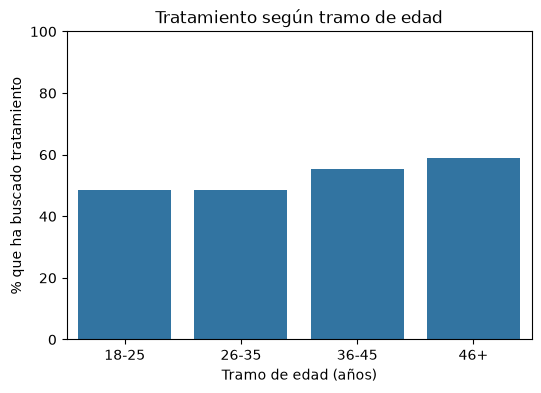

In [86]:
plt.figure(figsize=(6, 4))
sns.barplot(x=tabla_age.index, y=tabla_age["Yes"])
plt.title("Tratamiento según tramo de edad")
plt.xlabel("Tramo de edad (años)")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()


**Qué vemos:** el porcentaje de personas que ha buscado tratamiento es casi igual en los tramos 18-25 (48,4 %) y 26-35 (48,6 %), y sube en 36-45 (55,2 %) y en 46+ (58,9 %). La diferencia entre el tramo más bajo y el más alto es de unos 10 puntos.

**Interpretación:** parece haber una tendencia suave a buscar más tratamiento con la edad, pero la diferencia es pequeña comparada con otras variables (como `family_history`). El tramo 46+ tiene solo 56 personas, así que su resultado es orientativo. Es una relación, no una causa.

**treatment según no_employees:**

In [90]:
tabla_emp = pd.crosstab(df_clean["no_employees"], df_clean["treatment"], normalize="index") * 100
tabla_emp.round(1)
orden_emp = ["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"]
tabla_emp.loc[orden_emp].round(1)


treatment,No,Yes
no_employees,,
1-5,43.8,56.2
6-25,55.9,44.1
26-100,48.1,51.9
100-500,46.0,54.0
500-1000,55.0,45.0
More than 1000,48.2,51.8


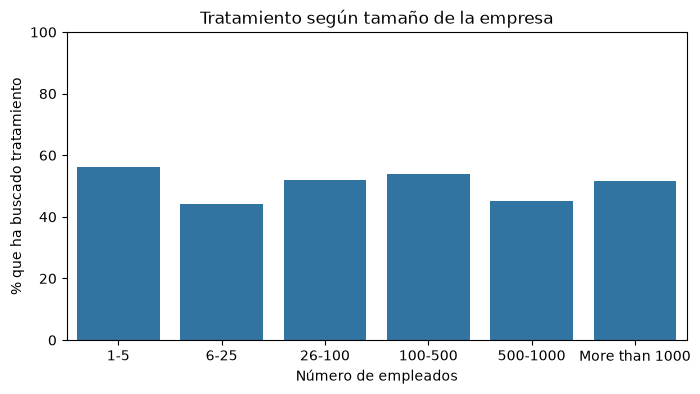

In [91]:
plt.figure(figsize=(8, 4))
sns.barplot(x=tabla_emp.index, y=tabla_emp["Yes"], order=orden_emp)
plt.title("Tratamiento según tamaño de la empresa")
plt.xlabel("Número de empleados")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()

**Qué vemos:** el porcentaje de personas que ha buscado tratamiento está entre el 44 % y el 56 % en todos los tamaños de empresa. El más bajo es 6-25 empleados (44,1 %) y el más alto es 1-5 (56,2 %). Los grupos de 26-100 (51,9 %), 100-500 (54,0 %) y más de 1000 (51,8 %) están en torno al 52 %.

**Interpretación:** no hay una tendencia clara entre el tamaño de la empresa y buscar tratamiento: ni sube ni baja de forma regular. La diferencia máxima (unos 12 puntos) es pequeña y el grupo 500-1000 tiene solo 60 personas, así que su resultado es orientativo. Es una relación, no una causa.

**treatment según remote_work:**

In [95]:
df_clean["remote_work"].value_counts()

remote_work
No     883
Yes    376
Name: count, dtype: int64

In [93]:
tabla_rw = pd.crosstab(df_clean["remote_work"], df_clean["treatment"], normalize="index") * 100
tabla_rw.round(1)


treatment,No,Yes
remote_work,,
No,50.3,49.7
Yes,47.3,52.7


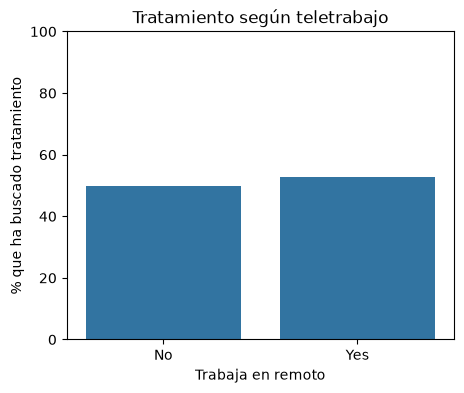

In [94]:
plt.figure(figsize=(5, 4))
sns.barplot(x=tabla_rw.index, y=tabla_rw["Yes"])
plt.title("Tratamiento según teletrabajo")
plt.xlabel("Trabaja en remoto")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()


**Qué vemos:** entre las personas que no trabajan en remoto, el 49,7 % ha buscado tratamiento (439 de 883); entre las que sí, el 52,7 % (198 de 376). La diferencia es de solo 3 puntos.

**Interpretación:** no se ve una relación clara entre el teletrabajo y buscar tratamiento: los dos grupos están cerca del 50 % de toda la muestra. Los dos grupos son lo bastante grandes para fiarnos de este resultado. Es una relación, no una causa.

##### Resumen de la pregunta 1

Porcentaje de personas que ha buscado tratamiento (`treatment = Yes`) en cada relación:

| Relación | Resultado | Diferencia | Observación |
|---|---|---|---|
| `family_history` | No 35,5 % · Yes 74,2 % | 39 puntos | la diferencia más grande |
| `identities` | Male 45,5 % · Female 68,8 % · Trans / non-binary / other 78,6 % | 23 puntos (hombres y mujeres) | el grupo trans tiene solo 14 personas: orientativo |
| `Age` (tramos) | 18-25 48,4 % · 26-35 48,6 % · 36-45 55,2 % · 46+ 58,9 % | 10 puntos | tendencia suave; 46+ tiene solo 56 personas |
| `no_employees` | entre 44,1 % (6-25) y 56,2 % (1-5) | 12 puntos | sin tendencia clara; 500-1000 tiene solo 60 personas |
| `remote_work` | No 49,7 % · Yes 52,7 % | 3 puntos | casi sin diferencia |

#### 7.2.2 Pregunta 2: ¿Lo que ofrece la empresa cambia algo?

Objetivo: comparar el porcentaje de `treatment = Yes` con y sin cada tipo de apoyo. Ojo: una relación no prueba que el apoyo cause el tratamiento.

**treatment según benefits:**

In [98]:
df_clean["benefits"].value_counts()

benefits
Yes           477
Don't know    408
No            374
Name: count, dtype: int64

In [96]:
tabla_ben = pd.crosstab(df_clean["benefits"], df_clean["treatment"], normalize="index") * 100
tabla_ben.round(1)


treatment,No,Yes
benefits,,
Don't know,63.0,37.0
No,51.6,48.4
Yes,36.1,63.9


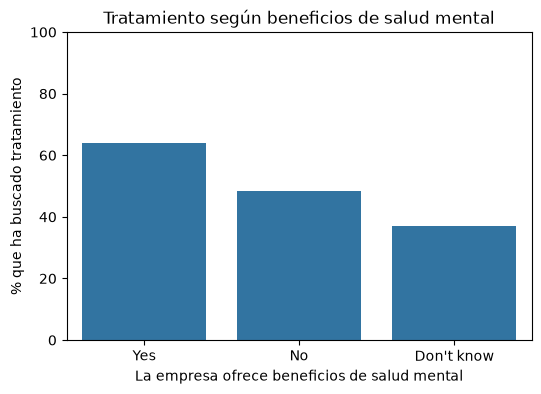

benefits
Yes           477
Don't know    408
No            374
Name: count, dtype: int64

In [ ]:
plt.figure(figsize=(6, 4))
sns.barplot(x=tabla_ben.index, y=tabla_ben["Yes"], order=["Yes", "No", "Don't know"])
plt.title("Tratamiento según beneficios de salud mental")
plt.xlabel("La empresa ofrece beneficios de salud mental")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()


**Qué vemos:** entre las personas cuya empresa ofrece beneficios de salud mental, el 63,9 % ha buscado tratamiento (305 de 477). Entre las que dicen que no hay beneficios, el 48,4 % (181 de 374), y entre las que no saben si los hay, el 37,0 % (151 de 408).

**Interpretación:**  buscar tratamiento es más frecuente donde hay beneficios (unos 15 puntos más que donde no los hay). El grupo «Don't know» es el más bajo y es un grupo aparte, no equivale a «No»: quien no sabe si hay beneficios quizá no los ha necesitado o buscado. La relación no prueba que los beneficios causen el tratamiento: también puede ser que quien busca tratamiento conozca mejor los beneficios de su empresa.

**treatment según care_options:**

In [99]:
df_clean["care_options"].value_counts()

care_options
No          501
Yes         444
Not sure    314
Name: count, dtype: int64

In [100]:
tabla_care = pd.crosstab(df_clean["care_options"], df_clean["treatment"], normalize="index") * 100
tabla_care.round(1)


treatment,No,Yes
care_options,,
No,58.7,41.3
Not sure,60.8,39.2
Yes,30.9,69.1


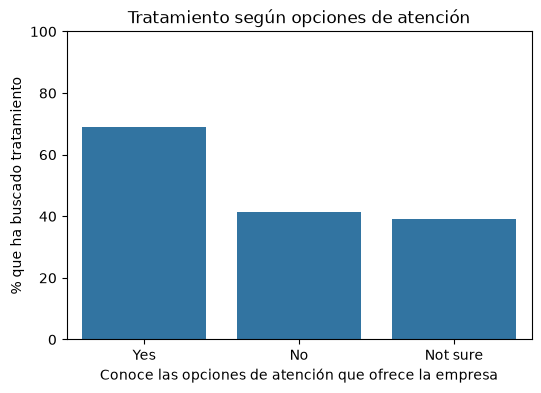

In [101]:
plt.figure(figsize=(6, 4))
sns.barplot(x=tabla_care.index, y=tabla_care["Yes"], order=["Yes", "No", "Not sure"])
plt.title("Tratamiento según opciones de atención")
plt.xlabel("Conoce las opciones de atención que ofrece la empresa")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()


**Qué vemos:** entre las personas que conocen las opciones de atención de su empresa, el 69,1 % ha buscado tratamiento (307 de 444). Entre las que dicen que no las conocen, el 41,3 % (207 de 501), y entre las que no están seguras, el 39,2 % (123 de 314).

**Interpretación:** conocer las opciones de atención va unido a buscar tratamiento mucho más a menudo (unos 28 puntos más que quien no las conoce). «No» y «Not sure» son casi iguales. La relación no prueba que conocer las opciones cause el tratamiento: también puede ser que quien busca tratamiento acabe conociendo mejor las opciones de su empresa.

**treatment según wellness_program:**

In [102]:
df_clean["wellness_program"].value_counts()

wellness_program
No            842
Yes           229
Don't know    188
Name: count, dtype: int64

In [103]:
tabla_wp = pd.crosstab(df_clean["wellness_program"], df_clean["treatment"], normalize="index") * 100
tabla_wp.round(1)


treatment,No,Yes
wellness_program,,
Don't know,56.9,43.1
No,50.1,49.9
Yes,40.6,59.4


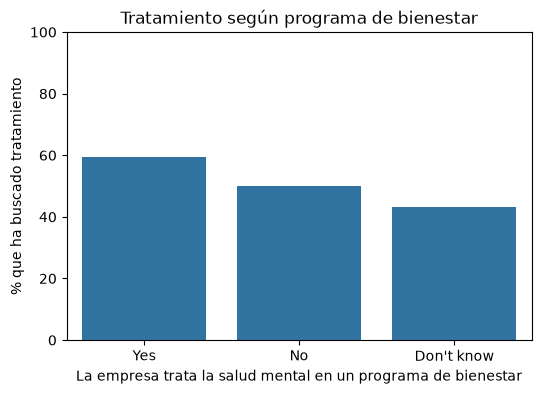

In [104]:
plt.figure(figsize=(6, 4))
sns.barplot(x=tabla_wp.index, y=tabla_wp["Yes"], order=["Yes", "No", "Don't know"])
plt.title("Tratamiento según programa de bienestar")
plt.xlabel("La empresa trata la salud mental en un programa de bienestar")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()


**Qué vemos:**  entre las personas cuya empresa trata la salud mental en un programa de bienestar, el 59,4 % ha buscado tratamiento (136 de 229). Entre las que dicen que no, el 49,9 % (420 de 842), y entre las que no saben, el 43,1 % (81 de 188). Los grupos son de tamaños muy distintos: la mayoría de las personas (842) responde «No».

**Interpretación:** buscar tratamiento es algo más frecuente donde hay programa de bienestar (unos 9 puntos más que donde no lo hay), pero la diferencia es menor que con `benefits` o `care_options`. El grupo «Don't know» es el más bajo y es un grupo aparte. La relación no prueba que el programa cause el tratamiento.

**treatment según seek_help:**

In [105]:
df_clean["seek_help"].value_counts()

seek_help
No            646
Don't know    363
Yes           250
Name: count, dtype: int64

In [106]:
tabla_sh = pd.crosstab(df_clean["seek_help"], df_clean["treatment"], normalize="index") * 100
tabla_sh.round(1)


treatment,No,Yes
seek_help,,
Don't know,54.3,45.7
No,50.0,50.0
Yes,40.8,59.2


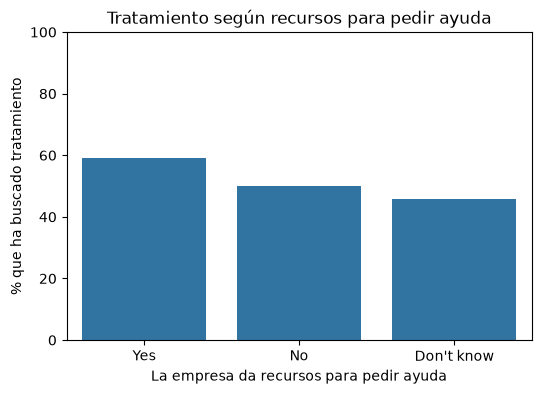

In [107]:
plt.figure(figsize=(6, 4))
sns.barplot(x=tabla_sh.index, y=tabla_sh["Yes"], order=["Yes", "No", "Don't know"])
plt.title("Tratamiento según recursos para pedir ayuda")
plt.xlabel("La empresa da recursos para pedir ayuda")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()


**Qué vemos:** entre las personas cuya empresa da recursos para pedir ayuda, el 59,2 % ha buscado tratamiento (148 de 250). Entre las que dicen que no, el 50,0 % (323 de 646), y entre las que no saben, el 45,7 % (166 de 363).

**Interpretación:** buscar tratamiento es algo más frecuente donde la empresa da recursos para pedir ayuda (unos 9 puntos más que donde no los da). El grupo «Don't know» es otra vez el más bajo. La relación no prueba que los recursos causen el tratamiento.

##### Resumen de la pregunta 2

Porcentaje de personas que ha buscado tratamiento (`treatment = Yes`) según cada tipo de apoyo de la empresa:

| Relación | Resultado | Diferencia | Observación |
|---|---|---|---|
| `benefits` | Yes 63,9 % · No 48,4 % · Don't know 37,0 % | 15 puntos (Yes y No) | «Don't know» es el más bajo y es un grupo aparte |
| `care_options` | Yes 69,1 % · No 41,3 % · Not sure 39,2 % | 28 puntos (Yes y No) | la diferencia más grande; mide conocer las opciones, no que existan |
| `wellness_program` | Yes 59,4 % · No 49,9 % · Don't know 43,1 % | 9,5 puntos (Yes y No) | grupos de tamaños muy distintos (229, 842, 188) |
| `seek_help` | Yes 59,2 % · No 50,0 % · Don't know 45,7 % | 9 puntos (Yes y No) | perfil parecido a `wellness_program` |

#### 7.2.3 Pregunta 3: ¿Proteger la confidencialidad reduce el miedo a hablar?

Objetivo: ver si las respuestas cambian según el nivel de anonimato (`Yes`, `No`, `Don't know`). `Don't know` es un grupo aparte, no se mezcla con `No`. El grupo `No` tiene solo 65 personas: los resultados serán orientativos.

**mental_health_consequence según anonymity:**

In [119]:
df_clean["anonymity"].value_counts()

anonymity
Don't know    819
Yes           375
No             65
Name: count, dtype: int64

In [120]:
tabla_mhc = pd.crosstab(df_clean["anonymity"], df_clean["mental_health_consequence"], normalize="index") * 100
tabla_mhc = tabla_mhc.loc[["Yes", "No", "Don't know"], ["No", "Maybe", "Yes"]]
tabla_mhc.round(1)


mental_health_consequence,No,Maybe,Yes
anonymity,,,
Yes,52.0,32.8,15.2
No,12.3,23.1,64.6
Don't know,35.0,41.4,23.6


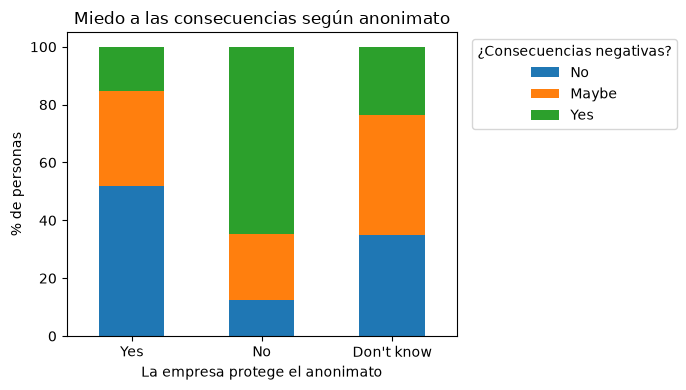

In [121]:
tabla_mhc.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.title("Miedo a las consecuencias según anonimato")
plt.xlabel("La empresa protege el anonimato")
plt.ylabel("% de personas")
plt.legend(title="¿Consecuencias negativas?", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Qué vemos:** entre las personas cuya empresa protege el anonimato, el 15,2 % cree que hablar de salud mental tendría consecuencias negativas (57 de 375) y el 52,0 % cree que no (195 de 375). Donde el anonimato no se protege, el 64,6 % teme consecuencias negativas (42 de 65). En el grupo «Don't know» (819 personas), el 23,6 % las teme y el 41,4 % responde «Maybe».

**Interpretación:**  el miedo a las consecuencias negativas es mucho menor donde se protege el anonimato (unos 49 puntos menos que donde no se protege), lo que va en el sentido de nuestra hipótesis. El grupo «No» tiene solo 65 personas, así que este resultado es orientativo. «Don't know» es un grupo aparte, con muchas respuestas «Maybe». La relación no prueba que el anonimato cause menos miedo.

**supervisor según anonymity:**

In [122]:
tabla_sup = pd.crosstab(df_clean["anonymity"], df_clean["supervisor"], normalize="index") * 100
tabla_sup = tabla_sup.loc[["Yes", "No", "Don't know"], ["No", "Some of them", "Yes"]]
tabla_sup.round(1)


supervisor,No,Some of them,Yes
anonymity,,,
Yes,21.3,24.3,54.4
No,58.5,20.0,21.5
Don't know,33.6,30.0,36.4


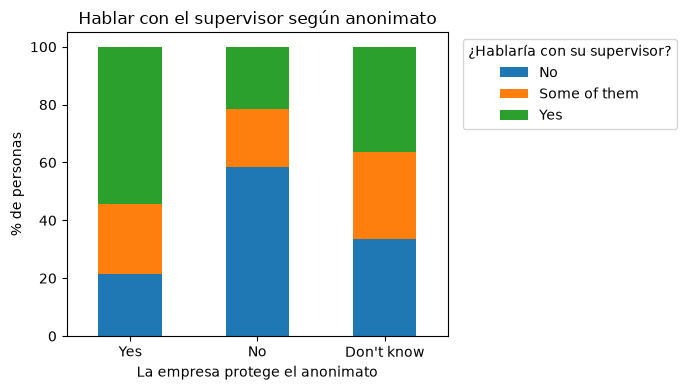

In [123]:
tabla_sup.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.title("Hablar con el supervisor según anonimato")
plt.xlabel("La empresa protege el anonimato")
plt.ylabel("% de personas")
plt.legend(title="¿Hablaría con su supervisor?", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Qué vemos:** entre las personas cuya empresa protege el anonimato, el 54,4 % hablaría con su supervisor (204 de 375) y el 21,3 % no lo haría. Donde el anonimato no se protege, la respuesta más frecuente es «No» (58,5 %) y solo el 21,5 % hablaría con su supervisor (14 de 65). En el grupo «Don't know», las respuestas están repartidas: 36,4 % «Yes», 30,0 % «Some of them» y 33,6 % «No».

**Interpretación:**  donde se protege el anonimato, bastante más gente hablaría con su supervisor (unos 33 puntos más que donde no se protege), lo que va en el sentido de nuestra hipótesis. El grupo «No» tiene solo 65 personas, así que el resultado es orientativo. «Some of them» y «Don't know» son grupos aparte. La relación no prueba que el anonimato cause que la gente hable.

**coworkers según anonymity:**

In [124]:
tabla_cow = pd.crosstab(df_clean["anonymity"], df_clean["coworkers"], normalize="index") * 100
tabla_cow = tabla_cow.loc[["Yes", "No", "Don't know"], ["No", "Some of them", "Yes"]]
tabla_cow.round(1)


coworkers,No,Some of them,Yes
anonymity,,,
Yes,16.8,60.5,22.7
No,40.0,47.7,12.3
Don't know,20.9,63.0,16.1


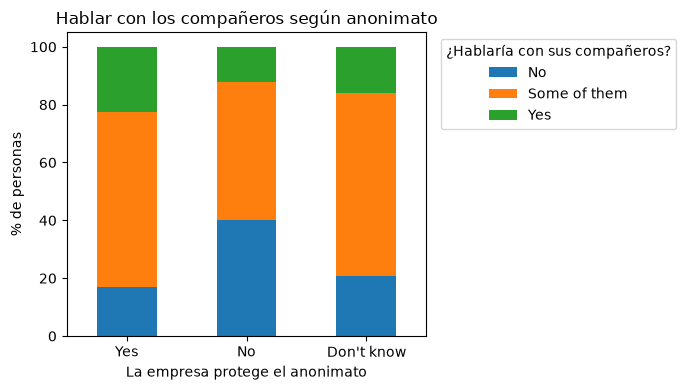

In [125]:
tabla_cow.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.title("Hablar con los compañeros según anonimato")
plt.xlabel("La empresa protege el anonimato")
plt.ylabel("% de personas")
plt.legend(title="¿Hablaría con sus compañeros?", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Qué vemos:** en los tres grupos, la respuesta más frecuente es «Some of them» (hablaría con algunos compañeros y con otros no): 60,5 % donde se protege el anonimato, 47,7 % donde no se protege y 63,0 % en «Don't know». El «Yes» es del 22,7 % donde se protege el anonimato (85 de 375) y del 12,3 % donde no se protege (8 de 65). El «No» sube al 40,0 % donde no se protege, frente al 16,8 % donde sí.

**Interpretación:**  con los compañeros, la mayoría responde «depende de quién», y la diferencia según el anonimato es mucho menor que con el supervisor (unos 10 puntos en «Yes»). Donde no se protege el anonimato hay más gente que no hablaría con ningún compañero, pero el grupo «No» tiene solo 65 personas, así que el resultado es orientativo. La relación no prueba que el anonimato cause que la gente hable.

##### Resumen de la pregunta 3

Cómo se reparten las respuestas según el nivel de anonimato (`anonymity`):

| Relación | Resultado | Diferencia | Observación |
|---|---|---|---|
| `mental_health_consequence` según `anonymity` | Teme consecuencias («Yes»): anonimato Yes 15,2 % · No 64,6 % · Don't know 23,6 % | 49 puntos | la diferencia más grande; el grupo «No» tiene solo 65 personas |
| `supervisor` según `anonymity` | Hablaría («Yes»): anonimato Yes 54,4 % · No 21,5 % · Don't know 36,4 % | 33 puntos | sin protección, «No» es la respuesta principal (58,5 %) |
| `coworkers` según `anonymity` | Hablaría («Yes»): anonimato Yes 22,7 % · No 12,3 % · Don't know 16,1 % | 10 puntos | domina «Some of them» en los tres grupos |

### 7.3 Valores atípicos (outliers)

Objetivo: detectar los valores atípicos de `Age` con la regla IQR y decidir qué hacer con ellos (conservar, limitar o eliminar), justificando la decisión.



In [75]:
q1 = df_clean["Age"].quantile(0.25)
q3 = df_clean["Age"].quantile(0.75)
iqr = q3 - q1
limite_bajo = q1 - 1.5 * iqr
limite_alto = q3 + 1.5 * iqr
limite_bajo, limite_alto

(np.float64(13.5), np.float64(49.5))

In [76]:
outliers = df_clean[(df_clean["Age"] < limite_bajo) | (df_clean["Age"] > limite_alto)]
len(outliers)

32

In [77]:
outliers["Age"].describe()

count    32.000000
mean     55.250000
std       5.028948
min      50.000000
25%      51.000000
50%      55.000000
75%      57.000000
max      72.000000
Name: Age, dtype: float64

**Regla:** un valor es atípico si está fuera del rango [13,5 ; 49,5] (regla IQR: Q1 − 1,5 x IQR y Q3 + 1,5 x IQR).

| Momento | Valores atípicos | Qué son | Decisión |
|---|---|---|---|
| Antes de limpiar (`df`, 1259 edades) | 40 | edades imposibles (-1726, 329, 99999999999...) y edades reales de 50 a 72 | separar los dos tipos |
| Sección 6.3 | 8 | edades imposibles (menores de 18 o mayores de 80) | pasan a NaN |
| Después de limpiar (`df_clean`, 1251 edades) | 32 (2,6 %) | edades reales de 50 a 72 años | se conservan |

**Decisión:** conservamos los 32 valores restantes porque son edades posibles (personas mayores que trabajan) y no errores de datos. Eliminarlos haría perder respuestas válidas y sesgaría el análisis hacia las personas más jóvenes. Solo representan el 2,6 % de las edades.

### 7.4 Agrupar y resumir

Objetivo: resumir los datos por grupos con `groupby` y `agg`, y cruzar dos factores con una tabla dinámica (`pivot_table`). Cada tabla lleva un comentario.

| Tabla | Herramienta | Qué resume |
|---|---|---|
| 1 | `groupby` + `agg` | `Age` por `identities` (número de personas, media y mediana) |
| 2 | `groupby` + `agg` | por `no_employees`: número de personas y % que ha buscado tratamiento |
| 3 | `pivot_table` | % que ha buscado tratamiento según `age_group` y `family_history` |


#### Columna auxiliar `treatment_yes`

Objetivo: crear una columna numérica que valga 1 si la persona ha buscado tratamiento y 0 si no.

Por qué: `treatment` es texto (`Yes` / `No`) y `groupby` no puede calcular una media con texto. Con 1 y 0, la media de un grupo es el porcentaje de personas que ha buscado tratamiento. Esta columna se usa en las tablas 2 y 3.

In [126]:
df_clean["treatment_yes"] = (df_clean["treatment"] == "Yes").astype(int)
df_clean[["treatment", "treatment_yes"]].head()

,treatment,treatment_yes
0,Yes,1
1,No,0
2,No,0
3,Yes,1
4,No,0


In [127]:
df_clean["treatment_yes"].mean() * 100

np.float64(50.5957108816521)

Qué hicimos: comparamos `treatment` con `"Yes"` (da `True` o `False`) y `.astype(int)` lo convierte en 1 o 0.

Verificación: las primeras filas muestran que `Yes` es 1 y `No` es 0, y la media de `treatment_yes` es 50,6 %, el mismo porcentaje que en el análisis univariado (7.1).

#### Tabla 1: edad por identidad (`groupby` + `agg`)

Objetivo: resumir `Age`, la única variable numérica, en cada grupo de `identities`.

`groupby("identities")` separa a las personas en tres grupos y `agg` calcula tres resúmenes por grupo: número de edades válidas (`count`), media (`mean`) y mediana (`median`).

In [128]:
df_clean.groupby("identities")["Age"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
identities,,,
Female,247,30.9,30.0
Male,989,32.4,32.0
Trans / non-binary / other,14,29.4,29.0


**Comentario:** la edad típica es parecida en los tres grupos: la mediana es de 32 años en los hombres, 30 en las mujeres y 29 en el grupo «Trans / non-binary / other». Los hombres son algo mayores (media de 32,4 años frente a 30,9 en las mujeres).

`count` suma 1250 y no 1255 (las personas con identidad válida) porque no cuenta las 5 edades que pasaron a NaN en la sección 6.3. El grupo «Trans / non-binary / other» tiene solo 14 personas, así que su resumen es orientativo.

#### Tabla 2: tamaño de la empresa y tratamiento (`groupby` + `agg`)

Objetivo: resumir en una sola tabla cuántas personas hay en cada tamaño de empresa y qué porcentaje ha buscado tratamiento.

Usamos `agg` con nombres: `size` cuenta las personas del grupo y la media de `treatment_yes` es la proporción que ha buscado tratamiento (por eso la multiplicamos por 100). `reindex` pone los tamaños en su orden natural.

In [129]:
orden_emp = ["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"]
tabla_resumen = df_clean.groupby("no_employees").agg(
    personas=("treatment_yes", "size"),
    pct_tratamiento=("treatment_yes", "mean"),
).reindex(orden_emp)
tabla_resumen["pct_tratamiento"] = (tabla_resumen["pct_tratamiento"] * 100).round(1)
tabla_resumen

,personas,pct_tratamiento
no_employees,,
1-5,162,56.2
6-25,290,44.1
26-100,289,51.9
100-500,176,54.0
500-1000,60,45.0
More than 1000,282,51.8


**Comentario:** el porcentaje de personas que ha buscado tratamiento está entre el 44,1 % (6-25 empleados) y el 56,2 % (1-5 empleados), sin una tendencia clara con el tamaño de la empresa. Son los mismos resultados que en la sección 7.2.1, ahora en una sola tabla.

El grupo de 500-1000 empleados tiene solo 60 personas, así que su 45,0 % es orientativo.

#### Tabla 3: edad y antecedentes familiares (`pivot_table`)

Objetivo: ver si el efecto de los antecedentes familiares sobre buscar tratamiento es el mismo en todos los tramos de edad. En la sección 7.2 miramos cada factor por separado; aquí cruzamos dos.

`pivot_table` coloca `age_group` en las filas y `family_history` en las columnas, y en cada celda calcula la media de `treatment_yes` (es decir, el porcentaje que ha buscado tratamiento). Con `aggfunc="size"` la segunda tabla cuenta las personas de cada celda.

In [130]:
tabla_pivot = df_clean.pivot_table(
    values="treatment_yes",
    index="age_group",
    columns="family_history",
    aggfunc="mean",
    observed=True,
) * 100
tabla_pivot.round(1)

family_history,No,Yes
age_group,,
18-25,31.0,73.9
26-35,33.1,74.1
36-45,41.9,73.5
46+,50.0,77.8


In [131]:
df_clean.pivot_table(
    values="treatment_yes",
    index="age_group",
    columns="family_history",
    aggfunc="size",
    observed=True,
)

family_history,No,Yes
age_group,,
18-25,129,88
26-35,435,266
36-45,160,117
46+,38,18


**Comentario:** entre las personas con antecedentes familiares, el porcentaje que ha buscado tratamiento es casi el mismo en todos los tramos (entre el 73,5 % y el 77,8 %). Entre las que no tienen antecedentes, sube con la edad: del 31,0 % (18-25) al 50,0 % (46+).

Así, la tendencia suave con la edad que vimos en 7.2.1 viene sobre todo de las personas sin antecedentes. Los antecedentes familiares se relacionan con buscar tratamiento a cualquier edad (entre 32 y 43 puntos más en los tres primeros tramos, y unos 28 en el tramo 46+).

Precaución: en el tramo 46+ hay solo 38 personas sin antecedentes y 18 con antecedentes, así que esa fila es orientativa. Es una relación, no una causa.

### 7.5 Ingeniería de variables (feature engineering)

Objetivo: crear variables nuevas a partir de las que ya tenemos, para que el análisis sea más claro.

| Variable | Dónde se creó | Qué resume | Dónde se usa |
|---|---|---|---|
| `age_group` | 7.2.1 | `Age` en 4 tramos | gráfico de 7.2.1 y tabla 3 de 7.4 |
| `identities` | 6.4 | `Gender` en 3 grupos | gráfico de 7.2.1 y tabla 1 de 7.4 |
| `support_score` | 7.5.3 | número de apoyos de la empresa (0 a 5) | gráfico de 7.5.3 |

`age_group` e `identities` ya estaban hechas. Aquí explicamos por qué las creamos y volvemos a mostrar el gráfico donde se usan. `support_score` es la única variable nueva de esta sección.

#### 7.5.1 `age_group`: la edad en tramos

**Qué es:** `Age` agrupada en 4 tramos: 18-25, 26-35, 36-45 y 46+ (`pd.cut`).

**Por qué la creamos:**
- `Age` tiene muchos valores distintos; un gráfico con una barra por edad sería ilegible y cada barra tendría muy pocas personas.
- Con 4 tramos, cada grupo es lo bastante grande para comparar porcentajes (217, 701, 277 y 56 personas).
- Probamos 5 tramos de 5 años: la tendencia era la misma y había más barras sin nada más que decir.

**Límite:** el tramo 46+ tiene solo 56 personas, así que su resultado es orientativo. Las 8 edades imposibles (puestas a NaN en 6.3) quedan fuera.

**Dónde se usa:** en 7.2.1 (gráfico de abajo) y en la tabla 3 de 7.4 (`pivot_table` con `family_history`).

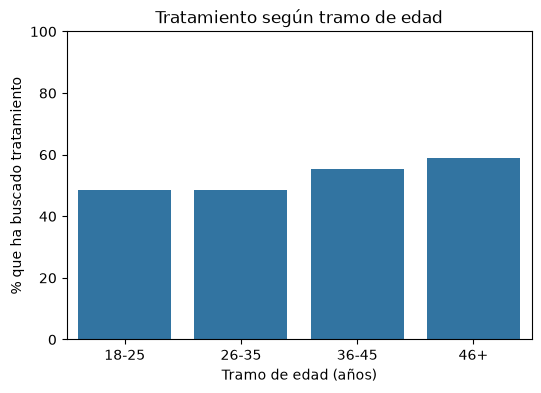

In [132]:
plt.figure(figsize=(6, 4))
sns.barplot(x=tabla_age.index, y=tabla_age["Yes"])
plt.title("Tratamiento según tramo de edad")
plt.xlabel("Tramo de edad (años)")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()

**Qué vemos:** el porcentaje que ha buscado tratamiento sube con la edad, del 48,4 % (18-25) al 58,9 % (46+). Sin agrupar la edad, esta tendencia suave no se vería.

#### 7.5.2 `identities`: el género en 3 grupos

**Qué es:** `Gender` agrupada en `Male`, `Female` y `Trans / non-binary / other`. Se creó en 6.4 porque `Gender` tenía 49 formas de escribirse.

**Por qué la creamos:**
- Con 49 valores no se puede comparar nada. 3 grupos permiten comparar porcentajes (994, 247 y 14 personas).
- `Gender` se mantiene sin tocar para el detalle; los análisis usan `identities`.
- El nombre `identities` lo pidió la profesora.

**Límite:** el tercer grupo reúne identidades distintas por una decisión práctica y tiene solo 14 personas, así que su resultado es orientativo. Las 4 respuestas que no eran un género quedan en NaN.

**Dónde se usa:** en 7.2.1 (gráfico de abajo) y en la tabla 1 de 7.4 (`groupby` con la edad).

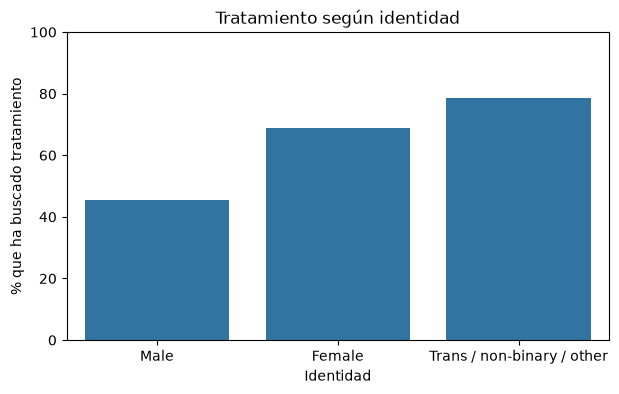

In [133]:
plt.figure(figsize=(7, 4))
sns.barplot(x=tabla_id.index, y=tabla_id["Yes"],
            order=["Male", "Female", "Trans / non-binary / other"])
plt.title("Tratamiento según identidad")
plt.xlabel("Identidad")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()

**Qué vemos:** el 45,5 % de los hombres ha buscado tratamiento, frente al 68,8 % de las mujeres y al 78,6 % del tercer grupo (solo 14 personas).

#### 7.5.3 `support_score`: cuánto apoyo ofrece la empresa

**Objetivo:** resumir en una sola columna cuántos de estos 5 apoyos de la empresa son «Yes»: `benefits`, `care_options`, `wellness_program`, `seek_help` y `anonymity`. El valor va de 0 (ninguno) a 5 (todos).

**Por qué la creamos:**
- En 7.2.2 comparamos las variables de apoyo una por una, pero tratan del mismo tema y se solapan: no son 4 pruebas independientes. Un score las resume en una sola variable.
- Responde a la pregunta 2 (¿lo que ofrece la empresa cambia algo?) con un solo gráfico: si el porcentaje de tratamiento sube con el score, se ve de un vistazo.
- Es fácil de explicar: se cuentan los «Yes».
- Añadimos `anonymity` a las 4 de 7.2.2 porque también es un apoyo que ofrece la empresa.

**Decisión sobre «Don't know» y «Not sure»:** solo «Yes» suma 1; «No», «Don't know» y «Not sure» valen 0. Consecuencia: un score bajo significa «no hay apoyo o la persona no lo sabe», no «seguro que no hay». Es una simplificación, y la anotamos como límite. Alternativa descartada: dar 0,5 a «Don't know»; complicaría el score sin una razón clara.

**Pasos:**
1. Mirar los valores de las 5 columnas (`value_counts`).
2. Crear `support_score`.
3. Comprobar que va de 0 a 5 y cuántas personas hay en cada valor.
4. Tabla y gráfico: % que ha buscado tratamiento según el score.
5. Comentario: qué vemos, interpretación y precauciones.

**Paso 1: valores de las 5 columnas**

Primero comprobamos cómo se escriben las respuestas, para saber qué contar.

In [135]:
cols_apoyo = ["benefits", "care_options", "wellness_program", "seek_help", "anonymity"]
df_clean[cols_apoyo].apply(pd.Series.value_counts)

,benefits,care_options,wellness_program,seek_help,anonymity
Don't know,408.0,NaN,188.0,363.0,819.0
No,374.0,501.0,842.0,646.0,65.0
Not sure,NaN,314.0,NaN,NaN,NaN
Yes,477.0,444.0,229.0,250.0,375.0


**Paso 2: crear `support_score`**

`df_clean[cols_apoyo] == "Yes"` da True o False en cada celda; `.sum(axis=1)` suma por fila (True vale 1) y deja un número de 0 a 5 por persona.

In [136]:
df_clean["support_score"] = (df_clean[cols_apoyo] == "Yes").sum(axis=1)

**Paso 3: comprobación (valores y número de personas)**

In [137]:
df_clean["support_score"].value_counts().sort_index()

support_score
0    517
1    251
2    203
3    115
4     92
5     81
Name: count, dtype: int64

**Paso 4: tabla y gráfico (`treatment` según `support_score`)**

In [138]:
tabla_ss = pd.crosstab(df_clean["support_score"], df_clean["treatment"], normalize="index") * 100
tabla_ss.round(1)

treatment,No,Yes
support_score,,
0,63.2,36.8
1,47.0,53.0
2,41.4,58.6
3,29.6,70.4
4,34.8,65.2
5,33.3,66.7


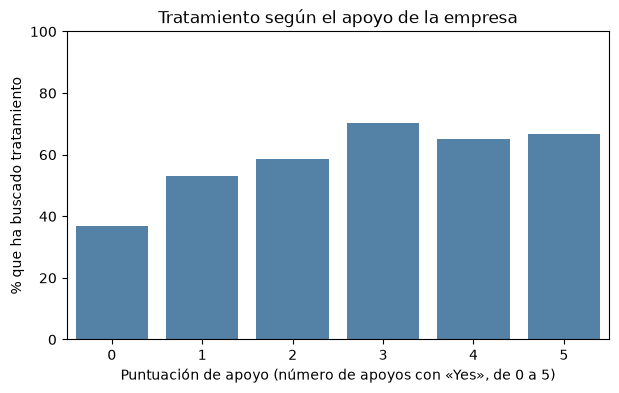

In [139]:
plt.figure(figsize=(7, 4))
sns.barplot(x=tabla_ss.index, y=tabla_ss["Yes"], color="steelblue")
plt.title("Tratamiento según el apoyo de la empresa")
plt.xlabel("Puntuación de apoyo (número de apoyos con «Yes», de 0 a 5)")
plt.ylabel("% que ha buscado tratamiento")
plt.ylim(0, 100)
plt.show()

**Qué vemos:** las respuestas están en las 5 columnas sin vacíos, y `support_score` va de 0 a 5. La mayoría de las personas tiene 0 apoyos (517, el 41,1 %); con 5 hay 81. El porcentaje que ha buscado tratamiento es del 36,8 % con score 0, 53,0 % con 1, 58,6 % con 2 y 70,4 % con 3. Con 4 y 5 no sigue subiendo: 65,2 % y 66,7 %.

**Interpretación:** sube con claridad del score 0 al 3 (unos 34 puntos más) y después se queda estable alrededor del 65-70 %. Más apoyos se relaciona con buscar más tratamiento, pero la relación no sigue subiendo en los scores altos. Las personas cuya empresa ofrece más recursos buscan tratamiento más a menudo, o los conocen mejor.

**Precauciones:**
- Los grupos más pequeños son los de score 5 (81 personas) y score 4 (92): sus porcentajes son orientativos, y la diferencia entre 3, 4 y 5 (menos de 6 puntos) es pequeña para ese tamaño.
- Relación no es causa: quien ya busca tratamiento puede conocer mejor los recursos de su empresa (dirección inversa), igual que en 7.2.2.
- «Don't know» y «Not sure» cuentan como 0, así que el grupo 0 mezcla empresas sin apoyo y personas que no lo saben.
- `anonymity` tiene 819 «Don't know»: pesa mucho en que el score 0 sea el grupo más grande.

#### Resumen de la sección 7.5

- `age_group`: la edad en 4 tramos hace legible la tendencia suave (del 48,4 % al 58,9 % de tratamiento).
- `identities`: el género en 3 grupos permite comparar; el tercer grupo (14 personas) es solo orientativo.
- `support_score`: resume 5 apoyos de la empresa en un número de 0 a 5; el tratamiento sube del 36,8 % (score 0) al 70,4 % (score 3) y después se estabiliza.
- Las tres columnas se usan en un gráfico. Ninguna se guarda en `survey_clean.csv` salvo `identities`, que viene de la limpieza.

### 7.6 Matriz de correlación y heatmap

Objetivo: ver de un vistazo qué variables se mueven juntas. Una correlación va de -1 a 1: cerca de 0 no hay relación, positiva significa que cuando una sube la otra también, negativa que cuando una sube la otra baja.

| Paso | Qué hacemos |
|---|---|
| 7.6.1 | pasar las columnas Yes/No a 0/1 (la correlación necesita números) |
| 7.6.2 | calcular la matriz y dibujar el heatmap |
| 7.6.3 | interpretar las relaciones más fuertes y los límites |

#### 7.6.1 Pasar las columnas a 0/1

**Qué columnas entran y por qué:**
- **Yes/No puras** (`treatment`, `family_history`, `remote_work`, `tech_company`, `obs_consequence`): `Yes` vale 1 y `No` vale 0.
- **Con más respuestas** (`benefits`, `care_options`, `wellness_program`, `seek_help`, `anonymity`, `mental_health_consequence`, `supervisor`, `coworkers`): 1 si la respuesta es `Yes` y 0 en cualquier otro caso, igual que en `support_score`. Así «Don't know», «Not sure», «Maybe» y «Some of them» cuentan como 0 (límite que anotamos abajo).
- **`identities` en 3 columnas** (`is_male`, `is_female`, `is_trans_other`): una por grupo, con 1 si la persona pertenece a ese grupo y 0 si no. No se puede usar una sola columna con 0, 1 y 2, porque la correlación leería un orden que no existe. Mantenemos los 3 grupos, como en el resto del análisis. Son NaN en las 4 personas sin identidad válida.
- **`Age`:** ya es numérica; las 8 edades imposibles siguen en NaN.

**Qué dejamos fuera:** `support_score` (es la suma de 5 columnas que ya están, y repetiría la información), `self_employed` (tiene 3 valores y solo 146 `Yes`), y las columnas con muchas categorías (`Country`, `no_employees`, `leave`, `work_interfere`).

**Por qué una tabla aparte (`df_num`):** así `df_clean` no cambia y las columnas originales siguen con su texto.

In [140]:
cols_si_no = ["treatment", "family_history", "remote_work", "tech_company", "obs_consequence"]
cols_yes = ["benefits", "care_options", "wellness_program", "seek_help", "anonymity",
            "mental_health_consequence", "supervisor", "coworkers"]

df_num = pd.DataFrame({c: (df_clean[c] == "Yes").astype(int) for c in cols_si_no + cols_yes})
for nombre, grupo in [("is_male", "Male"), ("is_female", "Female"),
                      ("is_trans_other", "Trans / non-binary / other")]:
    df_num[nombre] = (df_clean["identities"] == grupo).astype(float).where(df_clean["identities"].notna())
df_num["Age"] = df_clean["Age"]
df_num.shape

(1259, 17)

In [141]:
df_num.describe().loc[["count", "mean", "min", "max"]].round(2)

,treatment,family_history,remote_work,tech_company,obs_consequence,benefits,care_options,wellness_program,seek_help,anonymity,mental_health_consequence,supervisor,coworkers,is_male,is_female,is_trans_other,Age
count,1259.00,1259.00,1259.0,1259.00,1259.00,1259.00,1259.00,1259.00,1259.0,1259.0,1259.00,1259.00,1259.00,1255.00,1255.0,1255.00,1251.00
mean,0.51,0.39,0.3,0.82,0.15,0.38,0.35,0.18,0.2,0.3,0.23,0.41,0.18,0.79,0.2,0.01,32.08
min,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.0,0.00,18.00
max,1.00,1.00,1.0,1.00,1.00,1.00,1.00,1.00,1.0,1.0,1.00,1.00,1.00,1.00,1.0,1.00,72.00


**Qué hicimos:** comparamos cada columna con `"Yes"` (da True o False) y `.astype(int)` lo convierte en 1 o 0. Para las 3 columnas de identidad usamos `.where(...notna())` para dejar NaN donde no hay identidad.

**Verificación:** `df_num` tiene 17 columnas y 1259 filas. Las columnas 0/1 tienen mínimo 0 y máximo 1, y su media es el porcentaje de «Yes» (por ejemplo `treatment`: 0,51 = 50,6 %, como en 7.1). Las 3 columnas de identidad tienen 1255 valores y `Age` 1251.

#### 7.6.2 Matriz y heatmap

`df_num.corr()` calcula la correlación de Pearson entre cada par de columnas, ignorando los NaN de cada par. Entre dos columnas 0/1, esa correlación se llama coeficiente *phi*.

**Cómo leer el heatmap:** cada celda es una pareja de variables. Rojo = positiva, azul = negativa, blanco = casi cero. Ocultamos el triángulo de arriba porque repite el de abajo, y la diagonal (1 consigo misma) no aporta nada.

In [142]:
import numpy as np

corr = df_num.corr()
corr.round(2)

,treatment,family_history,remote_work,tech_company,obs_consequence,benefits,care_options,wellness_program,seek_help,anonymity,mental_health_consequence,supervisor,coworkers,is_male,is_female,is_trans_other,Age
treatment,1.00,0.38,0.03,-0.03,0.16,0.21,0.27,0.08,0.09,0.13,0.10,-0.04,0.06,-0.19,0.18,0.06,0.07
family_history,0.38,1.00,0.01,-0.05,0.12,0.15,0.12,0.05,0.06,0.05,0.08,0.00,0.01,-0.15,0.15,0.02,0.01
remote_work,0.03,0.01,1.00,0.13,-0.04,-0.09,0.02,-0.06,-0.05,0.00,0.03,0.04,0.08,0.02,-0.01,-0.04,0.15
tech_company,-0.03,-0.05,0.13,1.00,-0.06,-0.07,-0.03,-0.14,-0.12,-0.04,-0.07,0.05,0.07,0.07,-0.07,-0.01,-0.06
obs_consequence,0.16,0.12,-0.04,-0.06,1.00,0.02,0.10,0.08,0.09,0.02,0.22,-0.11,-0.06,-0.08,0.06,0.06,0.07
benefits,0.21,0.15,-0.09,-0.07,0.02,1.00,0.43,0.41,0.45,0.31,-0.03,0.02,-0.01,-0.14,0.14,-0.00,0.15
care_options,0.27,0.12,0.02,-0.03,0.10,0.43,1.00,0.31,0.33,0.39,0.02,0.05,0.03,-0.10,0.09,0.03,0.12
wellness_program,0.08,0.05,-0.06,-0.14,0.08,0.41,0.31,1.00,0.60,0.29,-0.02,0.09,0.02,-0.06,0.05,0.05,0.12
seek_help,0.09,0.06,-0.05,-0.12,0.09,0.45,0.33,0.60,1.00,0.32,-0.05,0.11,0.03,-0.04,0.04,0.00,0.18
anonymity,0.13,0.05,0.00,-0.04,0.02,0.31,0.39,0.29,0.32,1.00,-0.12,0.18,0.08,-0.03,0.02,0.03,0.03


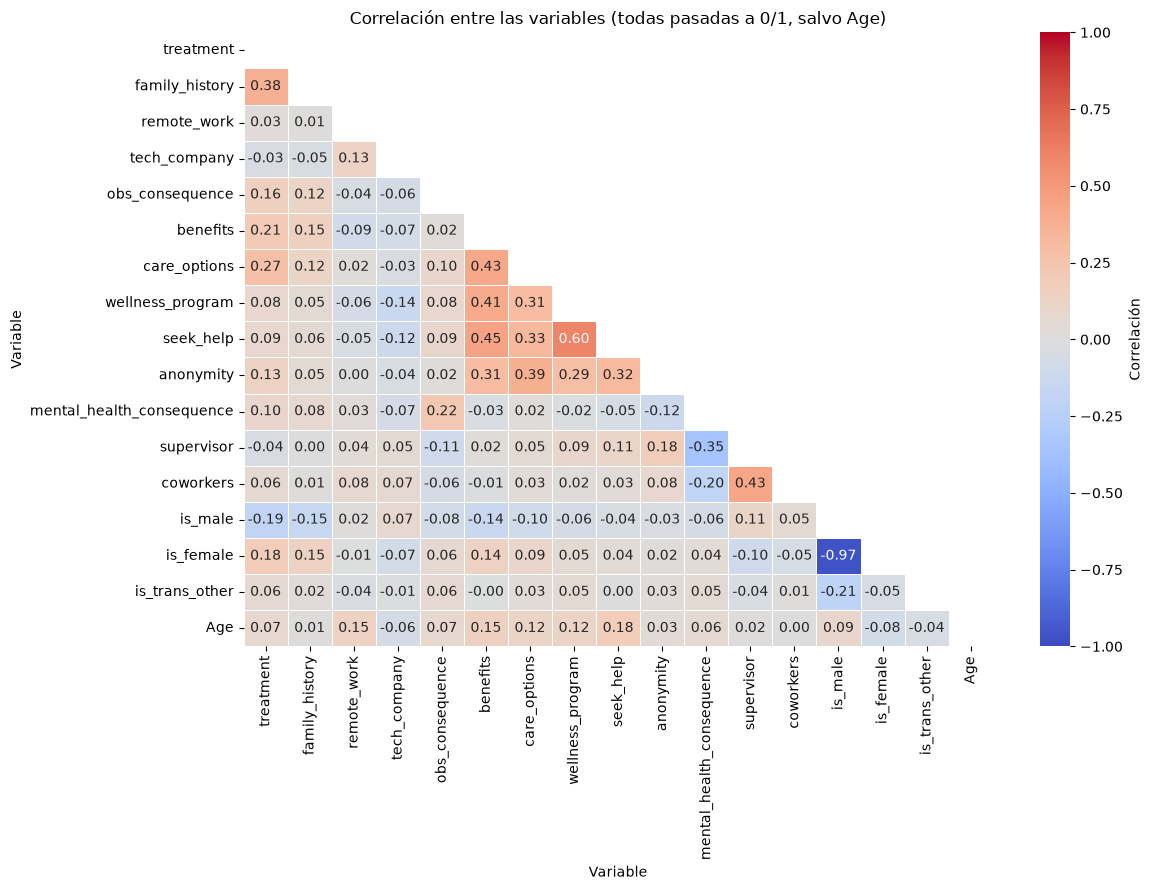

In [143]:
mascara = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Correlación"})
plt.title("Correlación entre las variables (todas pasadas a 0/1, salvo Age)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

#### 7.6.3 Interpretación

Primero miramos las correlaciones de `treatment` con las demás, ordenadas de mayor a menor fuerza, y después las parejas más fuertes de toda la matriz.

**Regla para leer el valor** (sin importar el signo): menos de 0,1 casi nada; de 0,1 a 0,3 débil; de 0,3 a 0,5 moderada; más de 0,5 fuerte.

In [144]:
corr["treatment"].drop("treatment").sort_values(key=abs, ascending=False).round(2)

family_history               0.38
care_options                 0.27
benefits                     0.21
is_male                     -0.19
is_female                    0.18
obs_consequence              0.16
anonymity                    0.13
mental_health_consequence    0.10
seek_help                    0.09
wellness_program             0.08
Age                          0.07
is_trans_other               0.06
coworkers                    0.06
supervisor                  -0.04
tech_company                -0.03
remote_work                  0.03
Name: treatment, dtype: float64

In [145]:
parejas = corr.where(~mascara).stack().sort_values(key=abs, ascending=False)
parejas.head(8).round(2)

is_female         is_male            -0.97
seek_help         wellness_program    0.60
                  benefits            0.45
coworkers         supervisor          0.43
care_options      benefits            0.43
wellness_program  benefits            0.41
anonymity         care_options        0.39
family_history    treatment           0.38
dtype: float64

**Qué vemos (`treatment`):**
- La más alta es `family_history` (0,38, moderada). Sigue `care_options` (0,27) y `benefits` (0,21), luego `is_male` (-0,19), `is_female` (0,18), `obs_consequence` (0,16), `anonymity` (0,13) y `mental_health_consequence` (0,10), todas débiles.
- `seek_help`, `wellness_program`, `Age`, `is_trans_other` (0,06), `coworkers`, `supervisor`, `tech_company` y `remote_work` quedan por debajo de 0,1: casi no hay relación lineal.
- `is_male` es negativa y `is_female` positiva: las mujeres buscan tratamiento más a menudo que los hombres (como en 7.2.1). El tercer grupo (`is_trans_other`) casi no se ve (0,06) aunque en 7.2.1 tenía el porcentaje más alto (78,6 %): con 14 personas pesa muy poco en la correlación.
- Ninguna variable pasa de 0,4: no hay una sola variable que explique `treatment`.

**Qué vemos (toda la matriz):**
- La pareja con el valor más alto es `is_male` – `is_female` (-0,97). Es normal: casi todas las personas son una de las dos, así que una columna es el espejo de la otra. No es un hallazgo, solo una consecuencia de tener los grupos separados.
- Entre variables de la encuesta, la más fuerte es `wellness_program` – `seek_help` (0,60): las empresas que tienen un programa de bienestar suelen dar también recursos para pedir ayuda.
- Después `benefits` – `seek_help` (0,45), `supervisor` – `coworkers` (0,43) y `benefits` – `care_options` (0,43).
- `mental_health_consequence` – `supervisor` es negativa (-0,35). No es un error: «Yes» significa cosas opuestas (temer consecuencias frente a hablar con el supervisor).

**Interpretación:**
- El resultado confirma lo de 7.2: `family_history` es lo que más se relaciona con buscar tratamiento, y el tamaño de la empresa y el trabajo remoto casi nada. `care_options` y `benefits` vuelven a destacar entre las variables de apoyo.
- Las variables de apoyo (`benefits`, `care_options`, `wellness_program`, `seek_help`, `anonymity`) forman un bloque rojo, con correlaciones de alrededor de 0,3 a 0,6 entre ellas: miden en parte lo mismo. Esto justifica el `support_score` de 7.5 y confirma que no son pruebas independientes.
- `supervisor` y `coworkers` forman otro bloque (el miedo a hablar y la disposición a hablar), separado del bloque de apoyo.

**Límites:**
- Correlación no es causa; además la dirección puede ser la inversa (quien busca tratamiento conoce mejor los recursos de su empresa).
- Con variables 0/1, la correlación mide solo si dos respuestas coinciden. Depende de cuántas personas hay en cada grupo: un «Yes» poco frecuente (por ejemplo `obs_consequence`, 184 personas) limita el valor máximo posible. Por eso no hay que comparar los números como si fueran porcentajes.
- Pasar todo a «Yes = 1, el resto = 0» pierde información: «Don't know» y «No» quedan juntos, aunque en 7.2 vimos que se comportan distinto.
- Solo detecta relaciones lineales y de dos en dos; no ve combinaciones (por ejemplo `family_history` y edad a la vez, como en la tabla 3 de 7.4).
- `Age` es la única variable no binaria, y su relación con `treatment` es débil (0,07), aunque en 7.2.1 vimos una tendencia suave: la correlación lineal casi no la ve.
- `is_trans_other` tiene solo 14 personas: su correlación es poco fiable y no se puede comparar con la de los grupos grandes.

### 7.7 Comparación de grupos: países

Objetivo: la issue pide una tendencia en el tiempo si los datos lo permiten y, si no, una comparación de grupos clara con una conclusión.

**Por qué no hacemos una tendencia en el tiempo:** `Timestamp` cubre de agosto de 2014 a febrero de 2016, pero 1190 de las 1259 respuestas son de 2014 (1135 solo de agosto de 2014), 68 son de 2015 y 1 de 2016 (ver 6.5). Una línea con un mes enorme y muchos meses de 1 a 5 respuestas no mostraría una tendencia, solo la diferencia de tamaño de la muestra. Por eso comparamos grupos, como permite el enunciado.

**Qué comparamos:** los 5 países con más respuestas (los mismos de 7.1, el 85,8 % de las respuestas). En 7.2 el país no entró en la pregunta 1, porque el 59,7 % de las respuestas es de EE. UU.; aquí lo usamos solo para comparar. Para cada país miramos dos cosas:
- el % de personas que ha buscado tratamiento (`treatment_yes`);
- el `support_score` medio (el apoyo que ofrece la empresa, de 0 a 5, creado en 7.5.3).

Así vemos si los países se parecen en quién busca tratamiento y en el apoyo que reciben.

In [ ]:
tabla_pais = (df_clean[df_clean["Country"].isin(top_countries.index)]
              .groupby("Country")
              .agg(personas=("treatment_yes", "size"),
                   pct_tratamiento=("treatment_yes", lambda x: x.mean() * 100),
                   support_medio=("support_score", "mean"))
              .round(1)
              .sort_values("personas", ascending=False))
tabla_pais

In [ ]:
etiquetas = [f"{pais}\n(n={n})" for pais, n in zip(tabla_pais.index, tabla_pais["personas"])]

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(x=tabla_pais.index, y=tabla_pais["pct_tratamiento"], ax=ejes[0], color="steelblue")
ejes[0].set_title("Tratamiento según el país")
ejes[0].set_xlabel("País (n = personas)")
ejes[0].set_ylabel("% que ha buscado tratamiento")
ejes[0].set_ylim(0, 100)
ejes[0].set_xticks(range(len(etiquetas)), etiquetas)

sns.barplot(x=tabla_pais.index, y=tabla_pais["support_medio"], ax=ejes[1], color="seagreen")
ejes[1].set_title("Apoyo de la empresa según el país")
ejes[1].set_xlabel("País (n = personas)")
ejes[1].set_ylabel("Puntuación de apoyo media (0 a 5)")
ejes[1].set_ylim(0, 5)
ejes[1].set_xticks(range(len(etiquetas)), etiquetas)

plt.tight_layout()
plt.show()

**Qué vemos:**
- **Tratamiento:** EE. UU. tiene el porcentaje más alto (54,6 %, 751 personas), seguido de Canadá (51,4 %), Reino Unido (50,3 %) y Alemania (46,7 %). Países Bajos queda más abajo (33,3 %), pero son solo 27 personas.
- **Apoyo de la empresa:** EE. UU. tiene una puntuación media de 1,7 y Canadá de 1,4; Reino Unido (0,8), Alemania (0,8) y Países Bajos (0,9) están en torno a 0,8.

**Conclusión:** los países se parecen mucho en quién busca tratamiento (entre el 47 % y el 55 % en los cuatro países con más de 30 personas), aunque las empresas de EE. UU. y Canadá ofrecen bastante más apoyo que las de Reino Unido, Alemania y Países Bajos. Es decir, más apoyo en el país no se traduce en una gran diferencia de tratamiento entre países. Esto es coherente con 7.5.3, donde el apoyo se relacionaba con el tratamiento dentro de las personas, pero no explica por sí solo las diferencias entre países.

**Precauciones:**
- Países Bajos (27 personas) y Alemania (45) son grupos pequeños: sus porcentajes son orientativos. Un cambio de una persona mueve el porcentaje de Países Bajos unos 4 puntos.
- La diferencia entre EE. UU. y Alemania (unos 8 puntos) es pequeña para esos tamaños.
- Relación no es causa. La encuesta es voluntaria y el perfil de quien responde cambia según el país (por ejemplo, el 24,0 % de las respuestas de EE. UU. son de mujeres, frente al 2,2 % de Alemania), así que parte de las diferencias puede venir de quién responde y no del país.

## 8. Respuesta a las preguntas de partida

Aquí respondemos a cada pregunta de la sección 2 con los resultados de la sección 7.2: primero la hipótesis, después lo que muestran los datos y por último si la hipótesis se confirma. Todos los porcentajes son porcentajes dentro de cada grupo.

### Pregunta 1: ¿Quién busca tratamiento?

**Hipótesis:** las personas con antecedentes familiares buscan tratamiento con más frecuencia; por identidad, el grupo `Female` es el que más lo busca; el tamaño de la empresa y el teletrabajo también podrían influir.

**Qué muestran los datos** (% de personas que ha buscado tratamiento):

| Factor | Resultado | Diferencia |
|---|---|---|
| `family_history` | No 35,5 % · Yes 74,2 % | 39 puntos |
| `identities` | Male 45,5 % · Female 68,8 % · Trans / non-binary / other 78,6 % | 23 puntos (hombres y mujeres) |
| `Age` (tramos) | 48,4 % · 48,6 % · 55,2 % · 58,9 % | 10 puntos |
| `no_employees` | entre 44,1 % y 56,2 % | 12 puntos, sin tendencia |
| `remote_work` | No 49,7 % · Yes 52,7 % | 3 puntos |

**Respuesta: hipótesis confirmada en parte.**

- **Confirmada:** tener antecedentes familiares es lo que más se relaciona con buscar tratamiento (74,2 % frente a 35,5 %). Entre hombres y mujeres, las mujeres lo buscan bastante más (68,8 % frente a 45,5 %).
- **No se puede confirmar del todo:** el grupo «Trans / non-binary / other» tiene el porcentaje más alto (78,6 %), pero son solo 14 personas, así que no podemos decir que `Female` sea el grupo que más busca tratamiento.
- **No confirmada:** el tamaño de la empresa y el teletrabajo no muestran una relación clara. La edad muestra una tendencia suave: el porcentaje sube a partir de los 36 años.

**Precauciones:** son relaciones, no causas. El grupo «Trans / non-binary / other» (14 personas), el tramo 46+ (56 personas) y las empresas de 500-1000 empleados (60 personas) son pequeños: sus resultados son orientativos.

### Pregunta 2: ¿Lo que ofrece la empresa cambia algo?

**Hipótesis:** en las empresas que ofrecen más apoyo, más gente busca tratamiento.

**Qué muestran los datos** (% de personas que ha buscado tratamiento):

| Apoyo | Yes | No | Don't know / Not sure | Diferencia (Yes y No) |
|---|---|---|---|---|
| `benefits` | 63,9 % | 48,4 % | 37,0 % | 15 puntos |
| `care_options` | 69,1 % | 41,3 % | 39,2 % | 28 puntos |
| `wellness_program` | 59,4 % | 49,9 % | 43,1 % | 9,5 puntos |
| `seek_help` | 59,2 % | 50,0 % | 45,7 % | 9 puntos |

**Respuesta: hipótesis confirmada.** En los cuatro tipos de apoyo, el grupo «Yes» busca tratamiento más a menudo que el grupo «No». La diferencia es grande con `care_options` (conocer las opciones de atención, 28 puntos) y más pequeña con `wellness_program` y `seek_help` (unos 9 puntos). El grupo «Don't know» es siempre el más bajo y es un grupo aparte.

**Precauciones:** una relación no prueba que el apoyo cause el tratamiento. También puede ser al revés: quien busca tratamiento conoce mejor los recursos de su empresa. Además, `care_options` mide si la persona *conoce* las opciones, no si la empresa las ofrece, y las cuatro variables hablan del mismo tema, así que no son cuatro pruebas independientes.

### Pregunta 3: ¿Proteger la confidencialidad reduce el miedo a hablar de salud mental en el trabajo?

**Hipótesis:** en las empresas que protegen el anonimato hay menos miedo a las consecuencias negativas y más gente hablaría con su supervisor y con sus compañeros.

**Qué muestran los datos** (por nivel de `anonymity`: Yes / No / Don't know):

| Variable | Resultado | Diferencia (Yes y No) |
|---|---|---|
| `mental_health_consequence`: teme consecuencias («Yes») | 15,2 % · 64,6 % · 23,6 % | 49 puntos |
| `supervisor`: hablaría («Yes») | 54,4 % · 21,5 % · 36,4 % | 33 puntos |
| `coworkers`: hablaría («Yes») | 22,7 % · 12,3 % · 16,1 % | 10 puntos |

**Respuesta: hipótesis confirmada, con distinta fuerza.**

- **Miedo a las consecuencias y supervisor:** la relación es clara. Donde se protege el anonimato, mucha menos gente teme consecuencias negativas (15,2 % frente a 64,6 %) y bastante más gente hablaría con su supervisor (54,4 % frente a 21,5 %).
- **Compañeros:** el sentido es el mismo, pero la diferencia es pequeña. En los tres grupos domina «Some of them» (entre el 47,7 % y el 63,0 %): con los compañeros la respuesta más común es «depende de quién».

**Precauciones:** el grupo `anonymity = No` tiene solo 65 personas, así que las diferencias son grandes pero orientativas. «Don't know» (819 personas) es un grupo aparte y no se mezcla con «No». Una relación no prueba que el anonimato cause menos miedo.

## 9. Conclusiones y límites

### 9.1 Conclusiones

Analizamos 1259 respuestas de la encuesta de OSMI (2014-2016) sobre salud mental en el sector tecnológico. La variable central es `treatment`: si la persona ha buscado tratamiento (50,6 % dice que sí, así que la variable está equilibrada).

**1. El factor que más se relaciona con buscar tratamiento son los antecedentes familiares.** El 74,2 % de las personas con antecedentes lo ha buscado, frente al 35,5 % de las que no los tienen (39 puntos de diferencia). Las mujeres lo buscan más que los hombres (68,8 % frente a 45,5 %). El tamaño de la empresa y el teletrabajo apenas cambian nada, y la edad muestra solo una tendencia suave.

**2. Las empresas que ofrecen o dan a conocer más apoyo tienen más gente que busca tratamiento.** Con los cuatro tipos de apoyo (`benefits`, `care_options`, `wellness_program` y `seek_help`), el grupo «Yes» busca tratamiento más a menudo que el grupo «No». La diferencia mayor es conocer las opciones de atención (69,1 % frente a 41,3 %). Quien no sabe si existe el apoyo («Don't know») es siempre quien menos busca tratamiento.

**3. Proteger el anonimato va unido a menos miedo a hablar.** Donde se protege el anonimato, el 15,2 % teme consecuencias negativas, frente al 64,6 % donde no se protege, y el 54,4 % hablaría con su supervisor, frente al 21,5 %. Con los compañeros la diferencia es mucho menor, porque la mayoría responde «depende de quién».

**Idea que une los tres resultados:** buscar tratamiento y hablar de salud mental es más frecuente cuando la persona tiene antecedentes que la hacen más cercana al tema, conoce los recursos de su empresa y se siente protegida. Que muchas personas respondan «Don't know» sugiere que la información sobre estos recursos no llega a todo el mundo.

### 9.2 Límites

- **Relaciones, no causas.** Una diferencia entre grupos no prueba que un factor cause otro. Por ejemplo, quien busca tratamiento puede acabar conociendo mejor los recursos de su empresa (la relación iría al revés). No hemos probado otros factores posibles, como si la salud mental ha afectado al trabajo (`work_interfere`), porque eso exigiría cruzar tres variables.
- **`treatment` no mide quién sufre.** Mide quién ha buscado tratamiento. Una persona puede necesitarlo y no haberlo buscado.
- **Grupos pequeños.** `Trans / non-binary / other` tiene 14 personas, `anonymity = No` tiene 65, el tramo de edad 46+ tiene 56 y las empresas de 500-1000 empleados tienen 60. Sus porcentajes cambian mucho con pocas respuestas, así que son solo orientativos.
- **Muestra poco equilibrada.** El 79,2 % son hombres y casi el 60 % responde desde Estados Unidos, por lo que los resultados no representan a todo el sector tecnológico ni a todos los países.
- **Respuestas en una sola época.** 1135 de las 1259 respuestas llegaron en agosto de 2014, así que no podemos estudiar cambios en el tiempo.
- **Participación voluntaria.** Es una encuesta que la gente decide contestar; probablemente responde más quien tiene interés en el tema. No sabemos si las personas que no respondieron piensan igual.
- **Datos que perdimos al limpiar.** 8 edades imposibles pasaron a NaN y 4 respuestas de `Gender` no válidas quedaron sin identidad: quedan fuera de las relaciones con `Age` e `identities`.
- **Variables muy parecidas.** Las cuatro variables de la pregunta 2 hablan del mismo tema, así que no son cuatro pruebas independientes.
